### Imports and configuration

In [5]:
from pathlib import Path
import os
import random
import warnings
import json
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Shared settings for problem B classification
SEQ_LEN = 1          # start with single-frame classification
STRIDE = 1
N_SPLITS = 10
VALIDATION_SPLIT = 0.10

BATCH_SIZE = 32
EPOCHS = 80
PATIENCE = 12
LEARNING_RATE = 1e-3

DEFAULT_OPTIMIZER = "adam"
DEFAULT_LOSS = "binary_cross_entropy"

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

# Paths
MOVENET_DIR = Path("../../../data/processed/movenet/csv_output")
KINECT_CUT_DIR = Path("../../../data/raw/kinect_good_preprocessed")
KINECT_UNCUT_DIR = Path("../../../data/raw/kinect_good_preprocessed_not_cut")

output_dir = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("MOVENET_DIR:", MOVENET_DIR)
print("KINECT_CUT_DIR:", KINECT_CUT_DIR)
print("KINECT_UNCUT_DIR:", KINECT_UNCUT_DIR)

DEVICE: cuda
GPU: NVIDIA GeForce RTX 2070
MOVENET_DIR: ..\..\..\data\processed\movenet\csv_output
KINECT_CUT_DIR: ..\..\..\data\raw\kinect_good_preprocessed
KINECT_UNCUT_DIR: ..\..\..\data\raw\kinect_good_preprocessed_not_cut


### MLFlow setup

In [6]:
load_dotenv("../../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A11_movenet_exercise_frame_classification_B"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A11_movenet_exercise_frame_classification_B


### MoveNet joint mapping and base feature definitions

In [7]:
# Assignment joint names for problem B
JOINTS_13 = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

# MoveNet -> assignment mapping
MOVENET_TO_ASSIGNMENT = {
    "nose": "head",
    "left_shoulder": "left_shoulder",
    "left_elbow": "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow": "right_elbow",
    "left_wrist": "left_hand",
    "right_wrist": "right_hand",
    "left_hip": "left_hip",
    "right_hip": "right_hip",
    "left_knee": "left_knee",
    "right_knee": "right_knee",
    "left_ankle": "left_foot",
    "right_ankle": "right_foot",
}

BASE_COORD_FEATURES = [f"{j}_{axis}" for j in JOINTS_13 for axis in ["x", "y"]]
BASE_SCORE_FEATURES = [f"{j}_score" for j in JOINTS_13]

FRAME_COL_CANDIDATES = ["frame_index", "FrameNo", "frame", "frame_no", "Frame", "frameno"]

print("Number of coordinate features:", len(BASE_COORD_FEATURES))
print("Number of score features:", len(BASE_SCORE_FEATURES))
print("Example coordinate features:", BASE_COORD_FEATURES[:8])

Number of coordinate features: 26
Number of score features: 13
Example coordinate features: ['head_x', 'head_y', 'left_shoulder_x', 'left_shoulder_y', 'left_elbow_x', 'left_elbow_y', 'right_shoulder_x', 'right_shoulder_y']


### Helper functions to clean MoveNet and derive labels from Kinect cut/uncut

In [8]:
def find_frame_col(df: pd.DataFrame) -> str:
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def strip_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    return df


def load_movenet_as_assignment_df(csv_path: str | Path) -> pd.DataFrame:
    """
    Converts a MoveNet CSV to the assignment's 13-joint format:
    head/shoulder/elbow/hand/hip/knee/foot with x,y and score.
    Drops eye/ear landmarks.
    """
    df = pd.read_csv(csv_path)
    df = strip_columns(df)

    frame_col = find_frame_col(df)
    out = pd.DataFrame()
    out["frame_index"] = df[frame_col].astype(int)

    if "timestamp_ms" in df.columns:
        out["timestamp_ms"] = df["timestamp_ms"]

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"
            if src not in df.columns:
                raise ValueError(f"Missing expected MoveNet column: {src}")
            out[dst] = pd.to_numeric(df[src], errors="coerce")

    return out.sort_values("frame_index").reset_index(drop=True)


def load_kinect_cut_bounds(cut_csv_path: str | Path, uncut_csv_path: str | Path) -> tuple[int, int]:
    """
    Uses the cut Kinect file to infer start/stop frame numbers within the uncut sequence.
    """
    cut_df = strip_columns(pd.read_csv(cut_csv_path))
    uncut_df = strip_columns(pd.read_csv(uncut_csv_path))

    if "FrameNo" not in cut_df.columns or "FrameNo" not in uncut_df.columns:
        raise ValueError("Expected 'FrameNo' in Kinect files.")

    start_frame = int(cut_df["FrameNo"].min())
    stop_frame = int(cut_df["FrameNo"].max())

    if start_frame < int(uncut_df["FrameNo"].min()) or stop_frame > int(uncut_df["FrameNo"].max()):
        raise ValueError("Cut frame bounds fall outside uncut Kinect sequence.")

    return start_frame, stop_frame


def add_inside_exercise_label(df: pd.DataFrame, start_frame: int, stop_frame: int) -> pd.DataFrame:
    """
    Adds binary label:
    1 = inside exercise interval [start_frame, stop_frame]
    0 = outside exercise
    """
    out = df.copy()
    out["label"] = ((out["frame_index"] >= start_frame) & (out["frame_index"] <= stop_frame)).astype(int)
    return out


def summarize_missing_values(df: pd.DataFrame, cols: list[str]) -> pd.Series:
    return df[cols].isna().sum().sort_values(ascending=False)

### Loads our example files

In [9]:
EXAMPLE_MOVENET_PATH = "../../../data/processed/movenet/csv_output/A1.csv"
EXAMPLE_KINECT_CUT_PATH = "../../../data/raw/kinect_good_preprocessed/A1_kinect.csv"
EXAMPLE_KINECT_UNCUT_PATH = "../../../data/raw/kinect_good_preprocessed_not_cut/A1_kinect_uncut.csv"

example_df = load_movenet_as_assignment_df(EXAMPLE_MOVENET_PATH)
start_frame, stop_frame = load_kinect_cut_bounds(
    EXAMPLE_KINECT_CUT_PATH,
    EXAMPLE_KINECT_UNCUT_PATH,
)
example_labeled_df = add_inside_exercise_label(example_df, start_frame, stop_frame)

print("Example MoveNet shape:", example_df.shape)
print("start_frame:", start_frame)
print("stop_frame:", stop_frame)
print("Labeled shape:", example_labeled_df.shape)

Example MoveNet shape: (229, 41)
start_frame: 68
stop_frame: 179
Labeled shape: (229, 42)


### Inspection cell

In [10]:
print("Columns:")
print(example_labeled_df.columns.tolist())

print("\nHead:")
display(example_labeled_df.head())

print("\nTail:")
display(example_labeled_df.tail())

print("\nClass balance:")
display(example_labeled_df["label"].value_counts().rename_axis("label").to_frame("count"))

print("\nClass proportions:")
display(
    example_labeled_df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .rename_axis("label")
    .to_frame("proportion")
)

print("\nMissing values in coordinate features:")
display(summarize_missing_values(example_labeled_df, BASE_COORD_FEATURES).head(10))

print("\nMissing values in score features:")
display(summarize_missing_values(example_labeled_df, BASE_SCORE_FEATURES).head(10))

print("\nFrame range:")
print(
    "min frame =", int(example_labeled_df["frame_index"].min()),
    "| max frame =", int(example_labeled_df["frame_index"].max()),
)

print("\nPositive interval check:")
display(
    example_labeled_df.loc[
        (example_labeled_df["frame_index"] >= start_frame - 2) &
        (example_labeled_df["frame_index"] <= stop_frame + 2),
        ["frame_index", "label"]
    ].head(10)
)
display(
    example_labeled_df.loc[
        (example_labeled_df["frame_index"] >= stop_frame - 2) &
        (example_labeled_df["frame_index"] <= stop_frame + 2),
        ["frame_index", "label"]
    ]
)

Columns:
['frame_index', 'timestamp_ms', 'head_x', 'head_y', 'head_score', 'left_shoulder_x', 'left_shoulder_y', 'left_shoulder_score', 'left_elbow_x', 'left_elbow_y', 'left_elbow_score', 'right_shoulder_x', 'right_shoulder_y', 'right_shoulder_score', 'right_elbow_x', 'right_elbow_y', 'right_elbow_score', 'left_hand_x', 'left_hand_y', 'left_hand_score', 'right_hand_x', 'right_hand_y', 'right_hand_score', 'left_hip_x', 'left_hip_y', 'left_hip_score', 'right_hip_x', 'right_hip_y', 'right_hip_score', 'left_knee_x', 'left_knee_y', 'left_knee_score', 'right_knee_x', 'right_knee_y', 'right_knee_score', 'left_foot_x', 'left_foot_y', 'left_foot_score', 'right_foot_x', 'right_foot_y', 'right_foot_score', 'label']

Head:


,frame_index,timestamp_ms,head_x,head_y,head_score,left_shoulder_x,left_shoulder_y,left_shoulder_score,left_elbow_x,left_elbow_y,...,right_knee_x,right_knee_y,right_knee_score,left_foot_x,left_foot_y,left_foot_score,right_foot_x,right_foot_y,right_foot_score,label
0,0,0,993.07,254.03,0.5925,1056.36,359.17,0.6353,1100.42,484.91,...,898.88,795.75,0.6022,1053.61,987.20,0.5770,893.85,993.23,0.6112,0
1,1,67,991.21,256.81,0.5695,1056.20,360.31,0.6193,1105.60,491.12,...,899.03,795.98,0.5734,1053.80,986.89,0.5821,892.38,992.17,0.6116,0
2,2,133,990.47,254.91,0.5332,1055.22,360.52,0.6254,1103.39,495.75,...,898.47,797.13,0.5812,1055.37,988.47,0.5140,902.74,979.58,0.4692,0
3,3,200,990.90,256.25,0.5602,1056.90,361.00,0.6195,1099.85,491.32,...,897.93,794.30,0.5453,1054.11,983.71,0.5806,893.59,987.46,0.6358,0
4,4,267,992.43,253.66,0.5658,1056.48,360.97,0.6192,1100.51,493.44,...,899.22,796.75,0.5491,1054.14,988.56,0.4953,892.88,989.43,0.6483,0



Tail:


,frame_index,timestamp_ms,head_x,head_y,head_score,left_shoulder_x,left_shoulder_y,left_shoulder_score,left_elbow_x,left_elbow_y,...,right_knee_x,right_knee_y,right_knee_score,left_foot_x,left_foot_y,left_foot_score,right_foot_x,right_foot_y,right_foot_score,label
224,224,14933,1510.13,122.43,0.5731,1492.39,247.59,0.7328,1513.80,423.56,...,1310.92,801.62,0.4364,1314.81,968.02,0.3804,1327.27,1052.93,0.4588,0
225,225,15000,1504.89,119.00,0.4260,1491.72,245.27,0.7668,1516.30,429.36,...,1304.91,773.02,0.6131,1334.70,968.73,0.4040,1333.29,1054.60,0.4404,0
226,226,15067,1505.04,118.71,0.4183,1490.45,244.50,0.7770,1516.81,430.60,...,1314.16,790.16,0.5294,1337.50,968.03,0.3423,1333.51,1048.66,0.4973,0
227,227,15133,1503.26,119.45,0.3986,1489.20,246.56,0.7584,1517.63,439.64,...,1334.15,798.01,0.5810,1335.89,997.65,0.3666,1331.08,1042.13,0.5361,0
228,228,15200,1510.73,110.03,0.6307,1484.07,239.84,0.7133,1505.45,442.62,...,1323.13,799.94,0.6971,1368.30,1006.71,0.4706,1339.13,1064.76,0.5501,0



Class balance:


,count
label,
0,117
1,112


... (5 outputs left out)

head_score              0
left_shoulder_score     0
left_elbow_score        0
right_shoulder_score    0
right_elbow_score       0
left_hand_score         0
right_hand_score        0
left_hip_score          0
right_hip_score         0
left_knee_score         0
dtype: int64


Frame range:
min frame = 0 | max frame = 228

Positive interval check:


,frame_index,label
66,66,0
67,67,0
68,68,1
69,69,1
70,70,1
71,71,1
72,72,1
73,73,1
74,74,1
75,75,1


,frame_index,label
177,177,1
178,178,1
179,179,1
180,180,0
181,181,0


### Quick visual sanity check

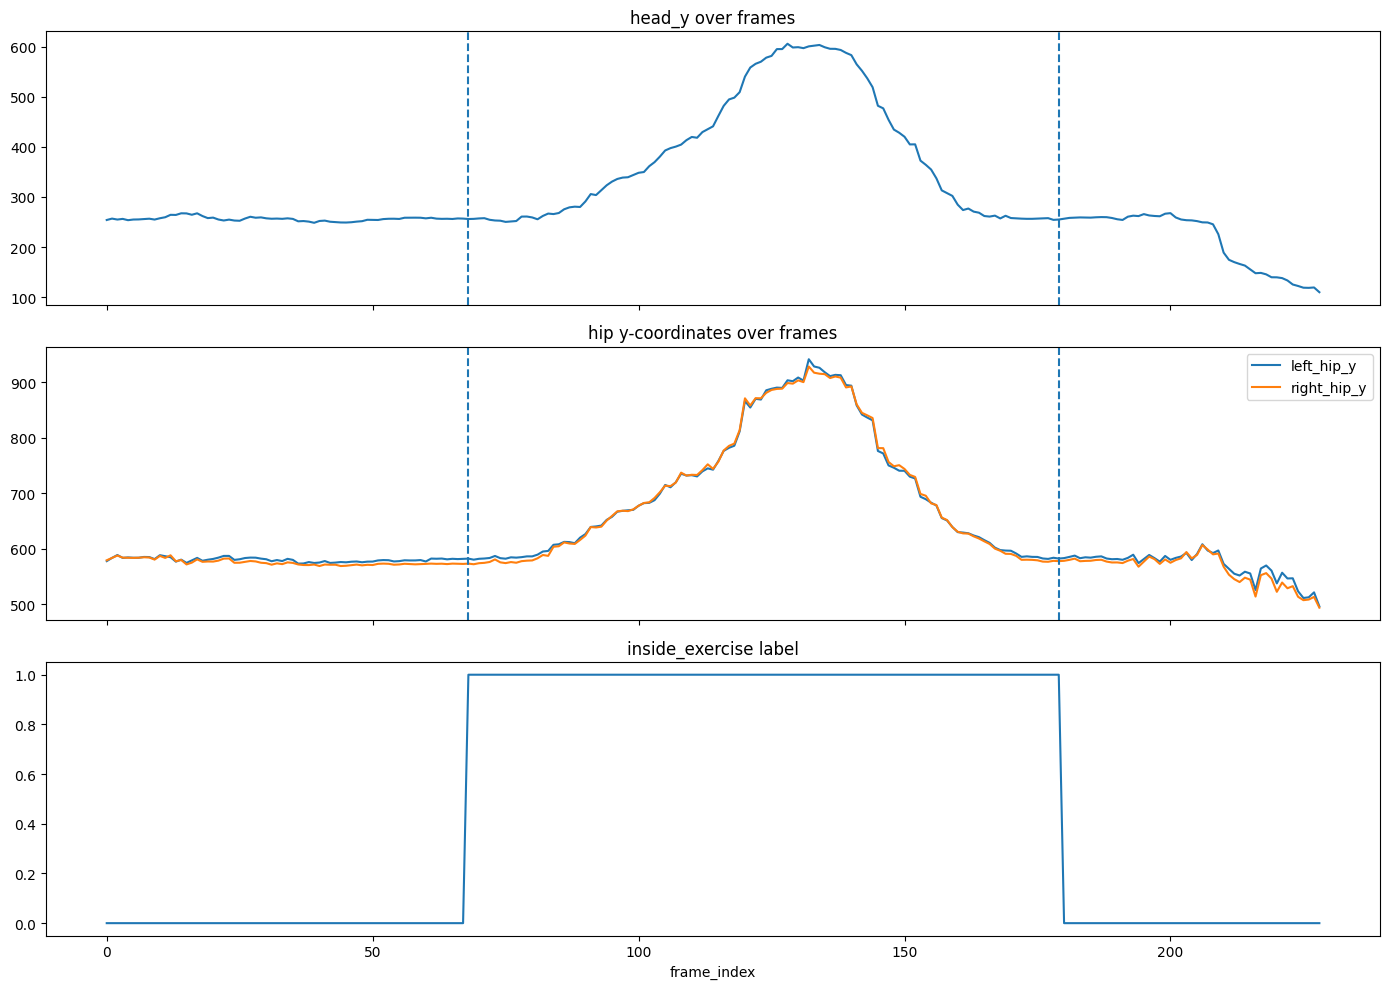

In [11]:
plot_df = example_labeled_df.copy()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(plot_df["frame_index"], plot_df["head_y"], label="head_y")
axes[0].axvline(start_frame, linestyle="--")
axes[0].axvline(stop_frame, linestyle="--")
axes[0].set_title("head_y over frames")

axes[1].plot(plot_df["frame_index"], plot_df["left_hip_y"], label="left_hip_y")
axes[1].plot(plot_df["frame_index"], plot_df["right_hip_y"], label="right_hip_y")
axes[1].axvline(start_frame, linestyle="--")
axes[1].axvline(stop_frame, linestyle="--")
axes[1].legend()
axes[1].set_title("hip y-coordinates over frames")

axes[2].plot(plot_df["frame_index"], plot_df["label"], label="label")
axes[2].set_title("inside_exercise label")
axes[2].set_xlabel("frame_index")

plt.tight_layout()
plt.show()

### Normalize coordinates, distance calculation, angles and velocity features

In [12]:
def add_normalized_coordinates(df: pd.DataFrame) -> pd.DataFrame:
    """
    Normalize x and y coordinates per frame using hip center and torso size.
    This reduces sensitivity to camera position / body translation / scale.
    """
    out = df.copy()

    out["hip_center_x"] = (out["left_hip_x"] + out["right_hip_x"]) / 2.0
    out["hip_center_y"] = (out["left_hip_y"] + out["right_hip_y"]) / 2.0

    out["shoulder_center_x"] = (out["left_shoulder_x"] + out["right_shoulder_x"]) / 2.0
    out["shoulder_center_y"] = (out["left_shoulder_y"] + out["right_shoulder_y"]) / 2.0

    torso_dx = out["shoulder_center_x"] - out["hip_center_x"]
    torso_dy = out["shoulder_center_y"] - out["hip_center_y"]
    out["torso_size"] = np.sqrt(torso_dx**2 + torso_dy**2)

    # avoid division by zero
    out["torso_size"] = out["torso_size"].replace(0, np.nan)
    out["torso_size"] = out["torso_size"].fillna(out["torso_size"].median())
    out["torso_size"] = out["torso_size"].clip(lower=1e-6)

    for joint in JOINTS_13:
        out[f"{joint}_x_norm"] = (out[f"{joint}_x"] - out["hip_center_x"]) / out["torso_size"]
        out[f"{joint}_y_norm"] = (out[f"{joint}_y"] - out["hip_center_y"]) / out["torso_size"]

    return out


def add_selected_distances(df: pd.DataFrame) -> pd.DataFrame:
    """
    Add a small set of normalized distances that are likely useful for squat detection.
    """
    out = df.copy()

    def dist(j1, j2, name):
        dx = out[f"{j1}_x_norm"] - out[f"{j2}_x_norm"]
        dy = out[f"{j1}_y_norm"] - out[f"{j2}_y_norm"]
        out[name] = np.sqrt(dx**2 + dy**2)

    dist("left_hip", "left_knee", "dist_left_hip_knee")
    dist("right_hip", "right_knee", "dist_right_hip_knee")
    dist("left_knee", "left_foot", "dist_left_knee_foot")
    dist("right_knee", "right_foot", "dist_right_knee_foot")
    dist("head", "left_hip", "dist_head_left_hip")
    dist("head", "right_hip", "dist_head_right_hip")
    dist("left_hand", "left_knee", "dist_left_hand_left_knee")
    dist("right_hand", "right_knee", "dist_right_hand_right_knee")
    dist("left_hip", "right_hip", "dist_hip_width")
    dist("left_shoulder", "right_shoulder", "dist_shoulder_width")

    return out


def add_selected_angles(df: pd.DataFrame) -> pd.DataFrame:
    """
    Add a few joint angles in 2D.
    Angle at point b from vectors ba and bc.
    """
    out = df.copy()

    def angle(a, b, c, name):
        bax = out[f"{a}_x_norm"] - out[f"{b}_x_norm"]
        bay = out[f"{a}_y_norm"] - out[f"{b}_y_norm"]
        bcx = out[f"{c}_x_norm"] - out[f"{b}_x_norm"]
        bcy = out[f"{c}_y_norm"] - out[f"{b}_y_norm"]

        dot = bax * bcx + bay * bcy
        norm1 = np.sqrt(bax**2 + bay**2)
        norm2 = np.sqrt(bcx**2 + bcy**2)
        denom = (norm1 * norm2).clip(lower=1e-6)

        cos_val = np.clip(dot / denom, -1.0, 1.0)
        out[name] = np.arccos(cos_val)

    angle("left_shoulder", "left_hip", "left_knee", "angle_left_hip")
    angle("right_shoulder", "right_hip", "right_knee", "angle_right_hip")
    angle("left_hip", "left_knee", "left_foot", "angle_left_knee")
    angle("right_hip", "right_knee", "right_foot", "angle_right_knee")
    angle("left_elbow", "left_shoulder", "left_hip", "angle_left_shoulder")
    angle("right_elbow", "right_shoulder", "right_hip", "angle_right_shoulder")

    return out


def add_simple_velocity_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Per-frame delta features for normalized coordinates.
    """
    out = df.copy()

    norm_cols = [f"{j}_{axis}_norm" for j in JOINTS_13 for axis in ["x", "y"]]
    for col in norm_cols:
        out[f"{col}_vel"] = out[col].diff().fillna(0.0)

    return out

### Test with example and double checking nothing is missing

In [13]:
example_feat_df = example_labeled_df.copy()
example_feat_df = add_normalized_coordinates(example_feat_df)
example_feat_df = add_selected_distances(example_feat_df)
example_feat_df = add_selected_angles(example_feat_df)
example_feat_df = add_simple_velocity_features(example_feat_df)

NORM_COORD_FEATURES = [f"{j}_{axis}_norm" for j in JOINTS_13 for axis in ["x", "y"]]
DISTANCE_FEATURES = [
    "dist_left_hip_knee",
    "dist_right_hip_knee",
    "dist_left_knee_foot",
    "dist_right_knee_foot",
    "dist_head_left_hip",
    "dist_head_right_hip",
    "dist_left_hand_left_knee",
    "dist_right_hand_right_knee",
    "dist_hip_width",
    "dist_shoulder_width",
]
ANGLE_FEATURES = [
    "angle_left_hip",
    "angle_right_hip",
    "angle_left_knee",
    "angle_right_knee",
    "angle_left_shoulder",
    "angle_right_shoulder",
]
VELOCITY_FEATURES = [f"{col}_vel" for col in NORM_COORD_FEATURES]

FEATURE_SETS = {
    "coords_only": BASE_COORD_FEATURES,
    "coords_plus_scores": BASE_COORD_FEATURES + BASE_SCORE_FEATURES,
    "norm_coords": NORM_COORD_FEATURES,
    "norm_coords_plus_scores": NORM_COORD_FEATURES + BASE_SCORE_FEATURES,
    "engineered_small": NORM_COORD_FEATURES + DISTANCE_FEATURES + ANGLE_FEATURES,
    "engineered_with_scores": NORM_COORD_FEATURES + DISTANCE_FEATURES + ANGLE_FEATURES + BASE_SCORE_FEATURES,
    "engineered_with_velocity": NORM_COORD_FEATURES + DISTANCE_FEATURES + ANGLE_FEATURES + VELOCITY_FEATURES,
}

for name, cols in FEATURE_SETS.items():
    print(f"{name:25s} -> {len(cols)} features")

coords_only               -> 26 features
coords_plus_scores        -> 39 features
norm_coords               -> 26 features
norm_coords_plus_scores   -> 39 features
engineered_small          -> 42 features
engineered_with_scores    -> 55 features
engineered_with_velocity  -> 68 features


In [14]:
display(
    example_feat_df[
        ["frame_index", "label"] +
        NORM_COORD_FEATURES[:6] +
        DISTANCE_FEATURES[:4] +
        ANGLE_FEATURES[:4]
    ].head()
)

print("Missing values in engineered_small:")
display(example_feat_df[FEATURE_SETS["engineered_small"]].isna().sum().sort_values(ascending=False).head(15))

,frame_index,label,head_x_norm,head_y_norm,left_shoulder_x_norm,left_shoulder_y_norm,left_elbow_x_norm,left_elbow_y_norm,dist_left_hip_knee,dist_right_hip_knee,dist_left_knee_foot,dist_right_knee_foot,angle_left_hip,angle_right_hip,angle_left_knee,angle_right_knee
0,0,0,0.071135,-1.490407,0.362252,-1.006791,0.564917,-0.428420,1.044498,1.007393,0.846177,0.908651,2.909053,2.961329,3.078058,3.029094
1,1,0,0.056576,-1.462733,0.347930,-0.998736,0.569394,-0.412307,0.988434,0.964916,0.827432,0.880037,2.903588,2.961017,3.055826,3.028644
2,2,0,0.051758,-1.469574,0.337586,-1.003377,0.550224,-0.406427,0.963224,0.937513,0.809496,0.805615,2.903881,2.946707,3.063408,2.961273
3,3,0,0.048659,-1.471695,0.345608,-1.000402,0.538849,-0.414063,0.976498,0.961161,0.830838,0.869289,2.911217,2.930985,3.075951,2.999147
4,4,0,0.055137,-1.481760,0.342720,-0.999941,0.540414,-0.405153,0.977726,0.970561,0.843894,0.865597,2.913881,2.938080,3.088301,3.013025


Missing values in engineered_small:


head_x_norm                   0
dist_head_right_hip           0
left_foot_y_norm              0
right_foot_x_norm             0
right_foot_y_norm             0
dist_left_hip_knee            0
dist_right_hip_knee           0
dist_left_knee_foot           0
dist_right_knee_foot          0
dist_head_left_hip            0
dist_left_hand_left_knee      0
head_y_norm                   0
dist_right_hand_right_knee    0
dist_hip_width                0
dist_shoulder_width           0
dtype: int64

### Windowing helpers for c frames

In [15]:
def make_sequence_windows(
    df: pd.DataFrame,
    feature_cols: list[str],
    label_col: str = "label",
    seq_len: int = 1,
    stride: int = 1,
    center_label: bool = True,
):
    """
    Convert one sequence dataframe into windowed samples.
    If seq_len=1, each sample is one frame.
    If seq_len>1, each sample is a fixed-length window.
    Label is taken from the center frame by default.
    """
    values = df[feature_cols].to_numpy(dtype=np.float32)
    labels = df[label_col].to_numpy(dtype=np.float32)
    frame_ids = df["frame_index"].to_numpy(dtype=np.int32)

    X_list = []
    y_list = []
    frame_ref_list = []

    if seq_len < 1:
        raise ValueError("seq_len must be >= 1")

    if seq_len == 1:
        for i in range(0, len(df), stride):
            X_list.append(values[i:i+1])
            y_list.append(labels[i])
            frame_ref_list.append(frame_ids[i])
    else:
        for start in range(0, len(df) - seq_len + 1, stride):
            end = start + seq_len
            window_x = values[start:end]

            if center_label:
                center_idx = start + seq_len // 2
                y_val = labels[center_idx]
                frame_ref = frame_ids[center_idx]
            else:
                y_val = labels[end - 1]
                frame_ref = frame_ids[end - 1]

            X_list.append(window_x)
            y_list.append(y_val)
            frame_ref_list.append(frame_ref)

    X = np.stack(X_list).astype(np.float32)
    y = np.array(y_list, dtype=np.float32)
    frame_refs = np.array(frame_ref_list, dtype=np.int32)

    return X, y, frame_refs


def flatten_if_needed(X: np.ndarray) -> np.ndarray:
    """
    Dense baseline will use flattened windows.
    Shape: (n_samples, seq_len, n_features) -> (n_samples, seq_len*n_features)
    """
    return X.reshape(X.shape[0], -1)

### Create first baseline dataset from the example file

In [16]:
BASELINE_FEATURE_SET_NAME = "engineered_small"
BASELINE_FEATURES = FEATURE_SETS[BASELINE_FEATURE_SET_NAME]

SEQ_LEN = 1
STRIDE = 1

X_example, y_example, frame_refs_example = make_sequence_windows(
    example_feat_df,
    feature_cols=BASELINE_FEATURES,
    label_col="label",
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

X_example_flat = flatten_if_needed(X_example)

print("Feature set:", BASELINE_FEATURE_SET_NAME)
print("X_example shape:", X_example.shape)
print("X_example_flat shape:", X_example_flat.shape)
print("y_example shape:", y_example.shape)
print("Positive rate:", y_example.mean())
print("First 10 frame refs:", frame_refs_example[:10])

Feature set: engineered_small
X_example shape: (229, 1, 42)
X_example_flat shape: (229, 42)
y_example shape: (229,)
Positive rate: 0.48908296
First 10 frame refs: [0 1 2 3 4 5 6 7 8 9]


### Dataset class and dense classifier

In [17]:
class FrameWindowDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class DenseBinaryClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dims=(128, 64), dropout=0.2):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        logits = self.net(x).squeeze(1)
        return logits

### Train/validation split on the example file

In [18]:
X_train, X_val, y_train, y_val, frames_train, frames_val = train_test_split(
    X_example_flat,
    y_example,
    frame_refs_example,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
    stratify=y_example,
)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:", X_val.shape, y_val.shape)
print("Train positive rate:", y_train.mean())
print("Val positive rate:", y_val.mean())

Train shape: (206, 42) (206,)
Val shape: (23, 42) (23,)
Train positive rate: 0.49029127
Val positive rate: 0.47826087


### Standardization

In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Scaled train mean (approx):", X_train_scaled.mean().round(4))
print("Scaled train std (approx):", X_train_scaled.std().round(4))

Scaled train mean (approx): -0.0
Scaled train std (approx): 1.0


### Class imbalance handling

In [20]:
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)

pos_weight_value = n_neg / max(n_pos, 1)
pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=DEVICE)

print("n_neg:", n_neg)
print("n_pos:", n_pos)
print("pos_weight:", float(pos_weight_value))

n_neg: 105
n_pos: 101
pos_weight: 1.0396039603960396


### Training utilities

In [21]:
def get_optimizer(model: nn.Module, optimizer_name: str, learning_rate: float):
    optimizer_name = optimizer_name.lower()
    if optimizer_name == "adam":
        return torch.optim.Adam(model.parameters(), lr=learning_rate)
    elif optimizer_name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=learning_rate)
    elif optimizer_name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")


def evaluate_binary_classifier(model, loader, loss_fn, threshold=0.5):
    model.eval()

    losses = []
    all_probs = []
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            probs = torch.sigmoid(logits)
            preds = (probs >= threshold).float()

            losses.append(loss.item())
            all_probs.extend(probs.cpu().numpy().tolist())
            all_preds.extend(preds.cpu().numpy().tolist())
            all_targets.extend(y_batch.cpu().numpy().tolist())

    y_true = np.array(all_targets).astype(int)
    y_pred = np.array(all_preds).astype(int)

    metrics = {
        "loss": float(np.mean(losses)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, y_pred),
    }
    return metrics


def train_binary_classifier(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    learning_rate=1e-3,
    epochs=80,
    patience=12,
    pos_weight=None,
    threshold=0.5,
):
    optimizer = get_optimizer(model, optimizer_name, learning_rate)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    history = []
    best_state = None
    best_val_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        train_loss = float(np.mean(train_losses))
        val_metrics = evaluate_binary_classifier(model, val_loader, loss_fn, threshold=threshold)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],
        }
        history.append(row)

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch % 10 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:03d} | "
                f"train_loss={train_loss:.4f} | "
                f"val_loss={val_metrics['loss']:.4f} | "
                f"precision={val_metrics['precision']:.4f} | "
                f"recall={val_metrics['recall']:.4f} | "
                f"f1={val_metrics['f1']:.4f}"
            )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    history_df = pd.DataFrame(history)
    return model, history_df

### Train one baseline model on the example sequence

In [22]:
train_dataset = FrameWindowDataset(X_train_scaled, y_train)
val_dataset = FrameWindowDataset(X_val_scaled, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

input_dim = X_train_scaled.shape[1]
model = DenseBinaryClassifier(
    input_dim=input_dim,
    hidden_dims=(128, 64),
    dropout=0.2,
).to(DEVICE)

model, history_df = train_binary_classifier(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    learning_rate=LEARNING_RATE,
    epochs=EPOCHS,
    patience=PATIENCE,
    pos_weight=pos_weight_tensor,
    threshold=0.5,
)

history_df.tail()

Epoch 001 | train_loss=0.6463 | val_loss=0.5817 | precision=1.0000 | recall=0.6364 | f1=0.7778
Epoch 010 | train_loss=0.1295 | val_loss=0.0948 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 020 | train_loss=0.0769 | val_loss=0.0316 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 030 | train_loss=0.0754 | val_loss=0.0184 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 040 | train_loss=0.0484 | val_loss=0.0129 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 050 | train_loss=0.0408 | val_loss=0.0111 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 060 | train_loss=0.0304 | val_loss=0.0050 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 070 | train_loss=0.0261 | val_loss=0.0039 | precision=1.0000 | recall=1.0000 | f1=1.0000
Early stopping at epoch 78


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
73,74,0.025540,0.002165,1.0,1.0,1.0
74,75,0.024100,0.002306,1.0,1.0,1.0
75,76,0.025996,0.002568,1.0,1.0,1.0
76,77,0.031744,0.002298,1.0,1.0,1.0
77,78,0.054723,0.002447,1.0,1.0,1.0


### Inspect baseline validation performance

In [23]:
val_loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
val_metrics = evaluate_binary_classifier(model, val_loader, val_loss_fn, threshold=0.5)

print("Validation metrics:")
for k, v in val_metrics.items():
    if k != "confusion_matrix":
        print(f"{k}: {v}")

print("\nConfusion matrix:")
print(val_metrics["confusion_matrix"])

print("\nClassification report:")
with torch.no_grad():
    logits = model(torch.tensor(X_val_scaled, dtype=torch.float32, device=DEVICE))
    probs = torch.sigmoid(logits).cpu().numpy()
    preds = (probs >= 0.5).astype(int)

print(classification_report(y_val.astype(int), preds, zero_division=0))

Validation metrics:
loss: 0.0020984839648008347
precision: 1.0
recall: 1.0
f1: 1.0

Confusion matrix:
[[12  0]
 [ 0 11]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        11

    accuracy                           1.00        23
   macro avg       1.00      1.00      1.00        23
weighted avg       1.00      1.00      1.00        23



Note that from the validation score is not thrustworthy here. Think it's because I split one single sequence randomly inot train and validation, so the model sees nearly identical neightboring frames in both sets. For this task, it causes leakage. Adjacent squat frames are very similar so a random split makes the validation much too easy.

### File matching helpers 

In [24]:
import re

def stem_base(name: str) -> str:
    """
    Normalize file stem so A1.csv matches A1_kinect.csv and A1_kinect_uncut.csv.
    """
    stem = Path(name).stem
    stem = stem.replace("_kinect_uncut", "")
    stem = stem.replace("_kinect", "")
    return stem


def list_csv_files(folder: Path) -> list[Path]:
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")
    return sorted(folder.glob("*.csv"))


def build_file_triples(movenet_dir: Path, kinect_cut_dir: Path, kinect_uncut_dir: Path) -> pd.DataFrame:
    movenet_files = list_csv_files(movenet_dir)
    cut_files = list_csv_files(kinect_cut_dir)
    uncut_files = list_csv_files(kinect_uncut_dir)

    movenet_map = {stem_base(p.name): p for p in movenet_files}
    cut_map = {stem_base(p.name): p for p in cut_files}
    uncut_map = {stem_base(p.name): p for p in uncut_files}

    common_keys = sorted(set(movenet_map) & set(cut_map) & set(uncut_map))

    rows = []
    for key in common_keys:
        rows.append({
            "sequence_id": key,
            "movenet_path": str(movenet_map[key]),
            "kinect_cut_path": str(cut_map[key]),
            "kinect_uncut_path": str(uncut_map[key]),
        })

    triples_df = pd.DataFrame(rows)
    return triples_df

### Load all labeled sequences

In [25]:
def build_labeled_sequence_df(movenet_path, kinect_cut_path, kinect_uncut_path, sequence_id):
    seq_df = load_movenet_as_assignment_df(movenet_path)
    start_frame, stop_frame = load_kinect_cut_bounds(kinect_cut_path, kinect_uncut_path)
    seq_df = add_inside_exercise_label(seq_df, start_frame, stop_frame)
    seq_df["sequence_id"] = sequence_id
    seq_df["start_frame"] = start_frame
    seq_df["stop_frame"] = stop_frame
    return seq_df


def load_all_labeled_sequences(triples_df: pd.DataFrame) -> pd.DataFrame:
    all_parts = []

    for _, row in triples_df.iterrows():
        seq_df = build_labeled_sequence_df(
            row["movenet_path"],
            row["kinect_cut_path"],
            row["kinect_uncut_path"],
            row["sequence_id"],
        )
        all_parts.append(seq_df)

    if not all_parts:
        raise ValueError("No matched MoveNet/cut/uncut file triples found.")

    all_df = pd.concat(all_parts, ignore_index=True)
    return all_df

### Inspect matched files and full dataset

In [26]:
triples_df = build_file_triples(MOVENET_DIR, KINECT_CUT_DIR, KINECT_UNCUT_DIR)
print("Matched sequences:", len(triples_df))
display(triples_df.head())

all_df = load_all_labeled_sequences(triples_df)
print("All rows:", len(all_df))
print("Unique sequences:", all_df["sequence_id"].nunique())

display(
    all_df.groupby("sequence_id")["label"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"sum": "positive_frames", "mean": "positive_rate"})
    .head(10)
)

Matched sequences: 179


,sequence_id,movenet_path,kinect_cut_path,kinect_uncut_path
0,A1,..\..\..\data\processed\movenet\csv_output\A1.csv,..\..\..\data\raw\kinect_good_preprocessed\A1_...,..\..\..\data\raw\kinect_good_preprocessed_not...
1,A10,..\..\..\data\processed\movenet\csv_output\A10...,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...
2,A100,..\..\..\data\processed\movenet\csv_output\A10...,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...
3,A101,..\..\..\data\processed\movenet\csv_output\A10...,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...
4,A102,..\..\..\data\processed\movenet\csv_output\A10...,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...


All rows: 38003
Unique sequences: 179


,count,positive_frames,positive_rate
sequence_id,,,
A1,229,112,0.489083
A10,257,161,0.626459
A100,223,163,0.730942
A101,272,229,0.841912
A102,212,206,0.971698
A103,280,168,0.600000
A104,198,153,0.772727
A105,210,146,0.695238
A106,204,159,0.779412


### Add engineered features to all sequences

In [27]:
all_feat_df = all_df.copy()
all_feat_df = add_normalized_coordinates(all_feat_df)
all_feat_df = add_selected_distances(all_feat_df)
all_feat_df = add_selected_angles(all_feat_df)
all_feat_df = add_simple_velocity_features(all_feat_df)

print("Shape after feature engineering:", all_feat_df.shape)

display(
    all_feat_df[
        ["sequence_id", "frame_index", "label"] +
        NORM_COORD_FEATURES[:4] +
        DISTANCE_FEATURES[:2] +
        ANGLE_FEATURES[:2]
    ].head()
)

Shape after feature engineering: (38003, 118)


,sequence_id,frame_index,label,head_x_norm,head_y_norm,left_shoulder_x_norm,left_shoulder_y_norm,dist_left_hip_knee,dist_right_hip_knee,angle_left_hip,angle_right_hip
0,A1,0,0,0.071135,-1.490407,0.362252,-1.006791,1.044498,1.007393,2.909053,2.961329
1,A1,1,0,0.056576,-1.462733,0.347930,-0.998736,0.988434,0.964916,2.903588,2.961017
2,A1,2,0,0.051758,-1.469574,0.337586,-1.003377,0.963224,0.937513,2.903881,2.946707
3,A1,3,0,0.048659,-1.471695,0.345608,-1.000402,0.976498,0.961161,2.911217,2.930985
4,A1,4,0,0.055137,-1.481760,0.342720,-0.999941,0.977726,0.970561,2.913881,2.938080


### Build windows for all sequences

In [28]:
def make_windows_for_all_sequences(
    df: pd.DataFrame,
    feature_cols: list[str],
    seq_len: int = 1,
    stride: int = 1,
    label_col: str = "label",
):
    X_parts = []
    y_parts = []
    frame_ref_parts = []
    seq_id_parts = []
    start_parts = []
    stop_parts = []

    for sequence_id, seq_df in df.groupby("sequence_id"):
        seq_df = seq_df.sort_values("frame_index").reset_index(drop=True)

        X_seq, y_seq, frame_refs_seq = make_sequence_windows(
            seq_df,
            feature_cols=feature_cols,
            label_col=label_col,
            seq_len=seq_len,
            stride=stride,
            center_label=True,
        )

        X_parts.append(X_seq)
        y_parts.append(y_seq)
        frame_ref_parts.append(frame_refs_seq)
        seq_id_parts.append(np.array([sequence_id] * len(y_seq), dtype=object))
        start_parts.append(np.array([seq_df["start_frame"].iloc[0]] * len(y_seq)))
        stop_parts.append(np.array([seq_df["stop_frame"].iloc[0]] * len(y_seq)))

    X = np.concatenate(X_parts, axis=0)
    y = np.concatenate(y_parts, axis=0)
    frame_refs = np.concatenate(frame_ref_parts, axis=0)
    seq_ids = np.concatenate(seq_id_parts, axis=0)
    start_frames = np.concatenate(start_parts, axis=0)
    stop_frames = np.concatenate(stop_parts, axis=0)

    meta_df = pd.DataFrame({
        "sequence_id": seq_ids,
        "frame_ref": frame_refs,
        "label": y.astype(int),
        "start_frame": start_frames.astype(int),
        "stop_frame": stop_frames.astype(int),
    })

    return X, y.astype(np.float32), meta_df

### Proper grouped train/test split

In [29]:
def split_sequences_train_test(triples_df: pd.DataFrame, test_size=0.10, random_state=42):
    seq_ids = triples_df["sequence_id"].tolist()

    train_ids, test_ids = train_test_split(
        seq_ids,
        test_size=test_size,
        random_state=random_state,
    )

    return set(train_ids), set(test_ids)


train_sequence_ids, test_sequence_ids = split_sequences_train_test(
    triples_df,
    test_size=0.10,
    random_state=RANDOM_SEED,
)

print("Train sequences:", len(train_sequence_ids))
print("Test sequences:", len(test_sequence_ids))
print("Example test IDs:", sorted(list(test_sequence_ids))[:10])

Train sequences: 161
Test sequences: 18
Example test IDs: ['A113', 'A114', 'A117', 'A121', 'A138', 'A140', 'A159', 'A16', 'A17', 'A25']


### Fast experiment prep

In [30]:
FAST_FEATURE_SET_NAMES = [
    "coords_only",
    "norm_coords",
    "engineered_small",
]

FAST_SEQ_LENS = [1, 5]
FAST_HIDDEN_CONFIGS = [
    (64,),
    (128, 64),
]
FAST_DROPOUTS = [0.1, 0.3]
FAST_OPTIMIZERS = ["adam"]
FAST_BATCH_SIZE = 32
FAST_EPOCHS = 20
FAST_PATIENCE = 5
FAST_STRIDE = 1
FAST_THRESHOLD = 0.5

### Cross-validation helpers on training sequences only

In [31]:
def prepare_train_test_arrays(feature_set_name: str, seq_len: int):
    feature_cols = FEATURE_SETS[feature_set_name]

    train_df = all_feat_df[all_feat_df["sequence_id"].isin(train_sequence_ids)].copy()
    test_df = all_feat_df[all_feat_df["sequence_id"].isin(test_sequence_ids)].copy()

    X_train_all, y_train_all, meta_train = make_windows_for_all_sequences(
        train_df,
        feature_cols=feature_cols,
        seq_len=seq_len,
        stride=FAST_STRIDE,
    )

    X_test, y_test, meta_test = make_windows_for_all_sequences(
        test_df,
        feature_cols=feature_cols,
        seq_len=seq_len,
        stride=FAST_STRIDE,
    )

    return X_train_all, y_train_all, meta_train, X_test, y_test, meta_test


def run_one_fold(
    X_train_all_flat,
    y_train_all,
    meta_train,
    train_idx,
    val_idx,
    hidden_dims,
    dropout,
    optimizer_name,
    batch_size,
    epochs,
    patience,
    threshold=0.5,
):
    X_tr = X_train_all_flat[train_idx]
    y_tr = y_train_all[train_idx]
    X_va = X_train_all_flat[val_idx]
    y_va = y_train_all[val_idx]

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_va = scaler.transform(X_va)

    n_pos = int(y_tr.sum())
    n_neg = int(len(y_tr) - n_pos)
    pos_weight_value = n_neg / max(n_pos, 1)
    pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=DEVICE)

    train_dataset = FrameWindowDataset(X_tr, y_tr)
    val_dataset = FrameWindowDataset(X_va, y_va)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )

    model = DenseBinaryClassifier(
        input_dim=X_tr.shape[1],
        hidden_dims=hidden_dims,
        dropout=dropout,
    ).to(DEVICE)

    model, history_df = train_binary_classifier(
        model,
        train_loader,
        val_loader,
        optimizer_name=optimizer_name,
        learning_rate=LEARNING_RATE,
        epochs=epochs,
        patience=patience,
        pos_weight=pos_weight_tensor,
        threshold=threshold,
    )

    val_loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
    val_metrics = evaluate_binary_classifier(model, val_loader, val_loss_fn, threshold=threshold)

    return {
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "f1": val_metrics["f1"],
        "loss": val_metrics["loss"],
        "history_df": history_df,
    }

### Fast grouped CV experiment loop

In [32]:
def run_fast_cv_search():
    results = []

    for feature_set_name in FAST_FEATURE_SET_NAMES:
        for seq_len in FAST_SEQ_LENS:
            print(f"\n=== Feature set: {feature_set_name} | seq_len: {seq_len} ===")

            X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = prepare_train_test_arrays(
                feature_set_name=feature_set_name,
                seq_len=seq_len,
            )

            X_train_all_flat = flatten_if_needed(X_train_all)

            groups = meta_train["sequence_id"].values
            unique_train_sequences = np.unique(groups)
            n_splits_here = min(N_SPLITS, len(unique_train_sequences))

            if n_splits_here < 2:
                print("Skipping: not enough train sequences for grouped CV.")
                continue

            gkf = GroupKFold(n_splits=n_splits_here)

            for hidden_dims in FAST_HIDDEN_CONFIGS:
                for dropout in FAST_DROPOUTS:
                    for optimizer_name in FAST_OPTIMIZERS:
                        fold_rows = []

                        for fold, (train_idx, val_idx) in enumerate(
                            gkf.split(X_train_all_flat, y_train_all, groups=groups),
                            start=1,
                        ):
                            fold_result = run_one_fold(
                                X_train_all_flat=X_train_all_flat,
                                y_train_all=y_train_all,
                                meta_train=meta_train,
                                train_idx=train_idx,
                                val_idx=val_idx,
                                hidden_dims=hidden_dims,
                                dropout=dropout,
                                optimizer_name=optimizer_name,
                                batch_size=FAST_BATCH_SIZE,
                                epochs=FAST_EPOCHS,
                                patience=FAST_PATIENCE,
                                threshold=FAST_THRESHOLD,
                            )

                            result_row = {
                                "feature_set": feature_set_name,
                                "seq_len": seq_len,
                                "hidden_dims": str(hidden_dims),
                                "dropout": dropout,
                                "optimizer": optimizer_name,
                                "fold": fold,
                                "val_precision": fold_result["precision"],
                                "val_recall": fold_result["recall"],
                                "val_f1": fold_result["f1"],
                                "val_loss": fold_result["loss"],
                            }
                            fold_rows.append(result_row)
                            results.append(result_row)

                        fold_df = pd.DataFrame(fold_rows)
                        print(
                            f"hidden={hidden_dims}, dropout={dropout}, opt={optimizer_name} | "
                            f"mean_f1={fold_df['val_f1'].mean():.4f}, "
                            f"mean_precision={fold_df['val_precision'].mean():.4f}, "
                            f"mean_recall={fold_df['val_recall'].mean():.4f}"
                        )

    return pd.DataFrame(results)

### Running the fast search

In [33]:
fast_results_df = run_fast_cv_search()
print("Finished. Rows:", len(fast_results_df))
display(fast_results_df.head())


=== Feature set: coords_only | seq_len: 1 ===
Epoch 001 | train_loss=0.2500 | val_loss=0.2190 | precision=0.8967 | recall=0.9011 | f1=0.8989
Epoch 010 | train_loss=0.1771 | val_loss=0.2076 | precision=0.9222 | recall=0.8517 | f1=0.8855
Epoch 020 | train_loss=0.1620 | val_loss=0.2077 | precision=0.9099 | recall=0.9107 | f1=0.9103
Early stopping at epoch 20
Epoch 001 | train_loss=0.2417 | val_loss=0.2282 | precision=0.8851 | recall=0.8415 | f1=0.8628
Epoch 010 | train_loss=0.1746 | val_loss=0.1963 | precision=0.8933 | recall=0.8450 | f1=0.8685
Early stopping at epoch 14
Epoch 001 | train_loss=0.2519 | val_loss=0.2058 | precision=0.9536 | recall=0.8433 | f1=0.8951
Epoch 010 | train_loss=0.1764 | val_loss=0.2128 | precision=0.9266 | recall=0.9056 | f1=0.9160
Early stopping at epoch 11
Epoch 001 | train_loss=0.2526 | val_loss=0.2428 | precision=0.8896 | recall=0.8564 | f1=0.8727
Early stopping at epoch 6
Epoch 001 | train_loss=0.2494 | val_loss=0.1879 | precision=0.9214 | recall=0.8152 | f

,feature_set,seq_len,hidden_dims,dropout,optimizer,fold,val_precision,val_recall,val_f1,val_loss
0,coords_only,1,"(64,)",0.1,adam,1,0.919947,0.864146,0.891174,0.203322
1,coords_only,1,"(64,)",0.1,adam,2,0.896588,0.840551,0.867666,0.193892
2,coords_only,1,"(64,)",0.1,adam,3,0.933333,0.896670,0.914634,0.197836
3,coords_only,1,"(64,)",0.1,adam,4,0.889565,0.856425,0.872681,0.242806
4,coords_only,1,"(64,)",0.1,adam,5,0.927536,0.882515,0.904466,0.138972


### Summarize fast search

In [34]:
fast_summary_df = (
    fast_results_df
    .groupby(["feature_set", "seq_len", "hidden_dims", "dropout", "optimizer"], as_index=False)
    .agg(
        mean_val_precision=("val_precision", "mean"),
        std_val_precision=("val_precision", "std"),
        mean_val_recall=("val_recall", "mean"),
        std_val_recall=("val_recall", "std"),
        mean_val_f1=("val_f1", "mean"),
        std_val_f1=("val_f1", "std"),
        mean_val_loss=("val_loss", "mean"),
    )
    .sort_values(["mean_val_f1", "mean_val_precision", "mean_val_recall"], ascending=[False, False, False])
    .reset_index(drop=True)
)

display(fast_summary_df)

,feature_set,seq_len,hidden_dims,dropout,optimizer,mean_val_precision,std_val_precision,mean_val_recall,std_val_recall,mean_val_f1,std_val_f1,mean_val_loss
0,coords_only,5,"(128, 64)",0.1,adam,0.917255,0.027704,0.884744,0.034401,0.899861,0.011137,0.198068
1,coords_only,5,"(64,)",0.3,adam,0.911890,0.021201,0.879769,0.024410,0.895284,0.016348,0.192348
2,coords_only,5,"(128, 64)",0.3,adam,0.908927,0.023958,0.876900,0.045420,0.891748,0.021106,0.197713
3,coords_only,5,"(64,)",0.1,adam,0.907590,0.022952,0.873971,0.033646,0.890130,0.022574,0.191322
4,engineered_small,5,"(128, 64)",0.3,adam,0.911957,0.013277,0.867882,0.029148,0.889172,0.018826,0.204047
5,coords_only,1,"(64,)",0.3,adam,0.905820,0.022100,0.874142,0.033089,0.889083,0.013566,0.201398
6,norm_coords,5,"(128, 64)",0.3,adam,0.909839,0.022270,0.867761,0.034689,0.887737,0.018261,0.210051
7,coords_only,1,"(128, 64)",0.3,adam,0.902940,0.024554,0.866265,0.029509,0.883855,0.019382,0.203511
8,norm_coords,5,"(128, 64)",0.1,adam,0.904048,0.022812,0.865223,0.050121,0.883276,0.025495,0.217226
9,norm_coords,5,"(64,)",0.1,adam,0.903682,0.020998,0.861507,0.030888,0.881821,0.021469,0.211014


### Save fast search results

In [35]:
fast_results_path = output_dir / "a11_problem_b_fast_cv_results.csv"
fast_summary_path = output_dir / "a11_problem_b_fast_cv_summary.csv"

fast_results_df.to_csv(fast_results_path, index=False)
fast_summary_df.to_csv(fast_summary_path, index=False)

print("Saved:")
print(fast_results_path)
print(fast_summary_path)

Saved:
reporting\results\a11_problem_b_fast_cv_results.csv
reporting\results\a11_problem_b_fast_cv_summary.csv


### Select the current quick champion

In [36]:
CHAMPION_CONFIG = {
    "feature_set": "coords_only",
    "seq_len": 5,
    "hidden_dims": (128, 64),
    "dropout": 0.1,
    "optimizer": "adam",
    "batch_size": 32,
    "epochs": 20,
    "patience": 5,
    "threshold": 0.5,
}

CHAMPION_CONFIG

{'feature_set': 'coords_only',
 'seq_len': 5,
 'hidden_dims': (128, 64),
 'dropout': 0.1,
 'optimizer': 'adam',
 'batch_size': 32,
 'epochs': 20,
 'patience': 5,
 'threshold': 0.5}

### Prepare full train/test arrays for the champion

In [37]:
champion_feature_cols = FEATURE_SETS[CHAMPION_CONFIG["feature_set"]]

X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = prepare_train_test_arrays(
    feature_set_name=CHAMPION_CONFIG["feature_set"],
    seq_len=CHAMPION_CONFIG["seq_len"],
)

X_train_all_flat = flatten_if_needed(X_train_all)
X_test_flat = flatten_if_needed(X_test)

print("Train windows:", X_train_all_flat.shape, y_train_all.shape)
print("Test windows:", X_test_flat.shape, y_test.shape)

print("Train positive rate:", y_train_all.mean())
print("Test positive rate:", y_test.mean())

display(meta_train.head())
display(meta_test.head())

Train windows: (33521, 130) (33521,)
Test windows: (3766, 130) (3766,)
Train positive rate: 0.6425226
Test positive rate: 0.6325013


,sequence_id,frame_ref,label,start_frame,stop_frame
0,A1,2,0,68,179
1,A1,3,0,68,179
2,A1,4,0,68,179
3,A1,5,0,68,179
4,A1,6,0,68,179


,sequence_id,frame_ref,label,start_frame,stop_frame
0,A113,2,0,78,152
1,A113,3,0,78,152
2,A113,4,0,78,152
3,A113,5,0,78,152
4,A113,6,0,78,152


### Scale train/test and compute class weight

In [38]:
champion_scaler = StandardScaler()
X_train_all_scaled = champion_scaler.fit_transform(X_train_all_flat)
X_test_scaled = champion_scaler.transform(X_test_flat)

n_pos_train = int(y_train_all.sum())
n_neg_train = int(len(y_train_all) - n_pos_train)

champion_pos_weight_value = n_neg_train / max(n_pos_train, 1)
champion_pos_weight_tensor = torch.tensor(
    [champion_pos_weight_value],
    dtype=torch.float32,
    device=DEVICE,
)

print("n_neg_train:", n_neg_train)
print("n_pos_train:", n_pos_train)
print("champion_pos_weight:", float(champion_pos_weight_value))

n_neg_train: 11983
n_pos_train: 21538
champion_pos_weight: 0.5563654935462903


### Build a small validation split from training sequences only

In [39]:
train_seq_ids_sorted = sorted(meta_train["sequence_id"].unique())

seq_train_ids_sub, seq_val_ids_sub = train_test_split(
    train_seq_ids_sorted,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

seq_train_ids_sub = set(seq_train_ids_sub)
seq_val_ids_sub = set(seq_val_ids_sub)

train_mask_sub = meta_train["sequence_id"].isin(seq_train_ids_sub).values
val_mask_sub = meta_train["sequence_id"].isin(seq_val_ids_sub).values

X_train_sub = X_train_all_scaled[train_mask_sub]
y_train_sub = y_train_all[train_mask_sub]

X_val_sub = X_train_all_scaled[val_mask_sub]
y_val_sub = y_train_all[val_mask_sub]

meta_train_sub = meta_train.loc[train_mask_sub].reset_index(drop=True)
meta_val_sub = meta_train.loc[val_mask_sub].reset_index(drop=True)

print("Sub-train:", X_train_sub.shape, y_train_sub.shape)
print("Sub-val:", X_val_sub.shape, y_val_sub.shape)
print("Sub-train sequences:", meta_train_sub["sequence_id"].nunique())
print("Sub-val sequences:", meta_val_sub["sequence_id"].nunique())
print("Sub-train positive rate:", y_train_sub.mean())
print("Sub-val positive rate:", y_val_sub.mean())

Sub-train: (29941, 130) (29941,)
Sub-val: (3580, 130) (3580,)
Sub-train sequences: 144
Sub-val sequences: 17
Sub-train positive rate: 0.64079356
Sub-val positive rate: 0.65698326


### Train the champion model

In [40]:
train_dataset_sub = FrameWindowDataset(X_train_sub, y_train_sub)
val_dataset_sub = FrameWindowDataset(X_val_sub, y_val_sub)

train_loader_sub = DataLoader(
    train_dataset_sub,
    batch_size=CHAMPION_CONFIG["batch_size"],
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

val_loader_sub = DataLoader(
    val_dataset_sub,
    batch_size=CHAMPION_CONFIG["batch_size"],
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

champion_model = DenseBinaryClassifier(
    input_dim=X_train_all_scaled.shape[1],
    hidden_dims=CHAMPION_CONFIG["hidden_dims"],
    dropout=CHAMPION_CONFIG["dropout"],
).to(DEVICE)

champion_model, champion_history_df = train_binary_classifier(
    champion_model,
    train_loader_sub,
    val_loader_sub,
    optimizer_name=CHAMPION_CONFIG["optimizer"],
    learning_rate=LEARNING_RATE,
    epochs=CHAMPION_CONFIG["epochs"],
    patience=CHAMPION_CONFIG["patience"],
    pos_weight=champion_pos_weight_tensor,
    threshold=CHAMPION_CONFIG["threshold"],
)

display(champion_history_df.tail())

Epoch 001 | train_loss=0.2043 | val_loss=0.2030 | precision=0.8967 | recall=0.9001 | f1=0.8984
Early stopping at epoch 6


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
1,2,0.175405,0.208501,0.901104,0.867772,0.884124
2,3,0.164290,0.242166,0.874421,0.882228,0.878307
3,4,0.157572,0.284982,0.889033,0.875425,0.882177
4,5,0.152769,0.254120,0.905771,0.854167,0.879212
5,6,0.146551,0.291627,0.908877,0.822704,0.863647


### Plot champion training history

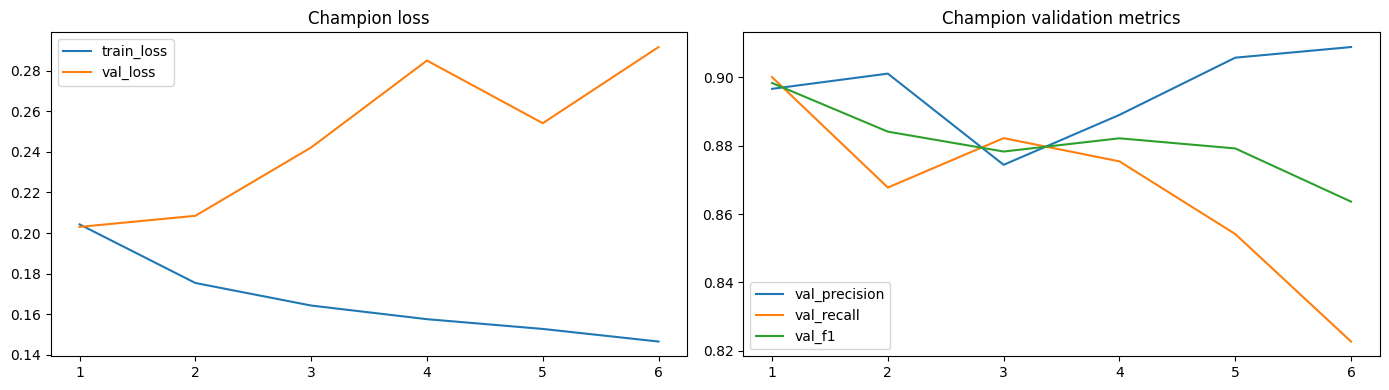

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(champion_history_df["epoch"], champion_history_df["train_loss"], label="train_loss")
axes[0].plot(champion_history_df["epoch"], champion_history_df["val_loss"], label="val_loss")
axes[0].set_title("Champion loss")
axes[0].legend()

axes[1].plot(champion_history_df["epoch"], champion_history_df["val_precision"], label="val_precision")
axes[1].plot(champion_history_df["epoch"], champion_history_df["val_recall"], label="val_recall")
axes[1].plot(champion_history_df["epoch"], champion_history_df["val_f1"], label="val_f1")
axes[1].set_title("Champion validation metrics")
axes[1].legend()

plt.tight_layout()
plt.show()

### Predict on the independent test set

In [42]:
champion_model.eval()

with torch.no_grad():
    test_logits = champion_model(
        torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE)
    )
    test_probs = torch.sigmoid(test_logits).cpu().numpy()
    test_preds = (test_probs >= CHAMPION_CONFIG["threshold"]).astype(int)

test_pred_df = meta_test.copy()
test_pred_df["prob"] = test_probs
test_pred_df["pred"] = test_preds
test_pred_df["label"] = y_test.astype(int)

display(test_pred_df.head())
print(test_pred_df.shape)

,sequence_id,frame_ref,label,start_frame,stop_frame,prob,pred
0,A113,2,0,78,152,0.000711,0
1,A113,3,0,78,152,0.000706,0
2,A113,4,0,78,152,0.000694,0
3,A113,5,0,78,152,0.000698,0
4,A113,6,0,78,152,0.000719,0


(3766, 7)


### Frame-level independent test metrics

In [43]:
test_precision = precision_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_recall = recall_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1 = f1_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1_macro = f1_score(test_pred_df["label"], test_pred_df["pred"], average="macro", zero_division=0)
test_f1_weighted = f1_score(test_pred_df["label"], test_pred_df["pred"], average="weighted", zero_division=0)
test_cm = confusion_matrix(test_pred_df["label"], test_pred_df["pred"])

print("Independent test metrics")
print("precision:", test_precision)
print("recall:", test_recall)
print("f1 (binary, class=1):", test_f1)
print("f1_macro:", test_f1_macro)
print("f1_weighted:", test_f1_weighted)

print("\nConfusion matrix:")
print(test_cm)

print("\nClassification report:")
print(classification_report(test_pred_df["label"], test_pred_df["pred"], zero_division=0))

Independent test metrics
precision: 0.909130624726955
recall: 0.8736356003358522
f1 (binary, class=1): 0.8910297580817812
f1_macro: 0.8565599681705656
f1_weighted: 0.8656945540259541

Confusion matrix:
[[1176  208]
 [ 301 2081]]

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.82      1384
           1       0.91      0.87      0.89      2382

    accuracy                           0.86      3766
   macro avg       0.85      0.86      0.86      3766
weighted avg       0.87      0.86      0.87      3766



### Per-sequence prediction summary

In [44]:
sequence_pred_summary = (
    test_pred_df.groupby("sequence_id")
    .agg(
        n_windows=("pred", "size"),
        n_true_positive_frames=("label", "sum"),
        n_pred_positive_frames=("pred", "sum"),
        mean_prob=("prob", "mean"),
        max_prob=("prob", "max"),
        start_frame=("start_frame", "first"),
        stop_frame=("stop_frame", "first"),
    )
    .reset_index()
)

display(sequence_pred_summary.head(20))

,sequence_id,n_windows,n_true_positive_frames,n_pred_positive_frames,mean_prob,max_prob,start_frame,stop_frame
0,A113,188,75,85,0.474181,1.0,78,152
1,A114,219,61,84,0.385012,1.0,125,185
2,A117,231,214,231,0.789304,1.0,0,215
3,A121,237,217,237,0.794025,1.0,0,218
4,A138,346,218,115,0.448517,1.0,69,286
5,A140,162,106,69,0.522244,1.0,6,111
6,A159,135,76,63,0.575552,1.0,47,122
7,A16,194,121,130,0.620193,1.0,30,150
8,A17,191,122,135,0.592683,1.0,21,142
9,A25,173,100,81,0.521501,1.0,32,131


### Start/stop frame extraction helpers

In [45]:
def longest_positive_run(frame_df: pd.DataFrame, pred_col: str = "pred") -> tuple[int | None, int | None]:
    """
    Returns the start and end frame of the longest consecutive predicted-positive run.
    If no positive run exists, returns (None, None).
    """
    frame_df = frame_df.sort_values("frame_ref").reset_index(drop=True)

    best_start = None
    best_end = None
    best_len = 0

    current_start = None
    current_end = None

    for _, row in frame_df.iterrows():
        frame_no = int(row["frame_ref"])
        is_pos = int(row[pred_col]) == 1

        if is_pos:
            if current_start is None:
                current_start = frame_no
                current_end = frame_no
            elif frame_no == current_end + 1:
                current_end = frame_no
            else:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len = run_len
                    best_start = current_start
                    best_end = current_end
                current_start = frame_no
                current_end = frame_no
        else:
            if current_start is not None:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len = run_len
                    best_start = current_start
                    best_end = current_end
                current_start = None
                current_end = None

    if current_start is not None:
        run_len = current_end - current_start + 1
        if run_len > best_len:
            best_len = run_len
            best_start = current_start
            best_end = current_end

    return best_start, best_end


def threshold_run_from_prob(
    frame_df: pd.DataFrame,
    prob_col: str = "prob",
    threshold: float = 0.5,
) -> tuple[int | None, int | None]:
    temp = frame_df.copy()
    temp["pred_tmp"] = (temp[prob_col] >= threshold).astype(int)
    return longest_positive_run(temp, pred_col="pred_tmp")

### Sequence-level application-context evaluation

In [46]:
sequence_rows = []

for sequence_id, seq_df in test_pred_df.groupby("sequence_id"):
    seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop = int(seq_df["stop_frame"].iloc[0])

    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    if pred_start is None or pred_stop is None:
        start_error = np.nan
        stop_error = np.nan
        abs_start_error = np.nan
        abs_stop_error = np.nan
        detected = 0
    else:
        start_error = pred_start - true_start
        stop_error = pred_stop - true_stop
        abs_start_error = abs(start_error)
        abs_stop_error = abs(stop_error)
        detected = 1

    sequence_rows.append({
        "sequence_id": sequence_id,
        "true_start": true_start,
        "true_stop": true_stop,
        "pred_start": pred_start,
        "pred_stop": pred_stop,
        "start_error_frames": start_error,
        "stop_error_frames": stop_error,
        "abs_start_error_frames": abs_start_error,
        "abs_stop_error_frames": abs_stop_error,
        "detected_segment": detected,
        "n_test_windows": len(seq_df),
        "n_true_positive_windows": int(seq_df["label"].sum()),
        "n_pred_positive_windows": int(seq_df["pred"].sum()),
        "mean_prob": float(seq_df["prob"].mean()),
        "max_prob": float(seq_df["prob"].max()),
    })

sequence_eval_df = pd.DataFrame(sequence_rows)
display(sequence_eval_df.head(20))

,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,n_test_windows,n_true_positive_windows,n_pred_positive_windows,mean_prob,max_prob
0,A113,78,152,85,152,7,0,7,0,1,188,75,85,0.474181,1.0
1,A114,125,185,120,203,-5,18,5,18,1,219,61,84,0.385012,1.0
2,A117,0,215,2,232,2,17,2,17,1,231,214,231,0.789305,1.0
3,A121,0,218,2,238,2,20,2,20,1,237,217,237,0.794025,1.0
4,A138,69,286,164,271,95,-15,95,15,1,346,218,115,0.448517,1.0
5,A140,6,111,32,100,26,-11,26,11,1,162,106,69,0.522244,1.0
6,A159,47,122,54,112,7,-10,7,10,1,135,76,63,0.575552,1.0
7,A16,30,150,37,147,7,-3,7,3,1,194,121,130,0.620193,1.0
8,A17,21,142,14,148,-7,6,7,6,1,191,122,135,0.592683,1.0
9,A25,32,131,41,118,9,-13,9,13,1,173,100,81,0.521501,1.0


### Summary of start/stop frame errors

In [47]:
sequence_eval_summary = pd.DataFrame({
    "metric": [
        "n_test_sequences",
        "n_detected_segments",
        "detection_rate",
        "mean_abs_start_error_frames",
        "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",
        "median_abs_stop_error_frames",
    ],
    "value": [
        len(sequence_eval_df),
        int(sequence_eval_df["detected_segment"].sum()),
        float(sequence_eval_df["detected_segment"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].median()),
        float(sequence_eval_df["abs_stop_error_frames"].mean()),
        float(sequence_eval_df["abs_stop_error_frames"].median()),
    ],
})

display(sequence_eval_summary)

,metric,value
0,n_test_sequences,18.000000
1,n_detected_segments,18.000000
2,detection_rate,1.000000
3,mean_abs_start_error_frames,19.222222
4,median_abs_start_error_frames,8.000000
5,mean_abs_stop_error_frames,9.888889
6,median_abs_stop_error_frames,10.500000


### Inspect worst and best sequence boundary predictions

In [48]:
sequence_eval_ranked = sequence_eval_df.copy()
sequence_eval_ranked["total_abs_boundary_error"] = (
    sequence_eval_ranked["abs_start_error_frames"].fillna(9999)
    + sequence_eval_ranked["abs_stop_error_frames"].fillna(9999)
)

print("Best boundary predictions:")
display(
    sequence_eval_ranked
    .sort_values("total_abs_boundary_error", ascending=True)
    .head(10)
)

print("Worst boundary predictions:")
display(
    sequence_eval_ranked
    .sort_values("total_abs_boundary_error", ascending=False)
    .head(10)
)

Best boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,n_test_windows,n_true_positive_windows,n_pred_positive_windows,mean_prob,max_prob,total_abs_boundary_error
0,A113,78,152,85,152,7,0,7,0,1,188,75,85,0.474181,1.0,7
17,B17,110,207,112,202,2,-5,2,5,1,267,98,91,0.357723,1.0,7
7,A16,30,150,37,147,7,-3,7,3,1,194,121,130,0.620193,1.0,10
8,A17,21,142,14,148,-7,6,7,6,1,191,122,135,0.592683,1.0,13
12,A57,64,254,50,253,-14,-1,14,1,1,252,190,204,0.720170,1.0,15
6,A159,47,122,54,112,7,-10,7,10,1,135,76,63,0.575552,1.0,17
2,A117,0,215,2,232,2,17,2,17,1,231,214,231,0.789305,1.0,19
3,A121,0,218,2,238,2,20,2,20,1,237,217,237,0.794025,1.0,22
9,A25,32,131,41,118,9,-13,9,13,1,173,100,81,0.521501,1.0,22
14,A6,30,172,46,165,16,-7,16,7,1,221,143,125,0.624562,1.0,23


Worst boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,n_test_windows,n_true_positive_windows,n_pred_positive_windows,mean_prob,max_prob,total_abs_boundary_error
4,A138,69,286,164,271,95,-15,95,15,1,346,218,115,0.448517,1.0,110
13,A59,2,214,60,202,58,-12,58,12,1,235,213,172,0.753912,1.0,70
5,A140,6,111,32,100,26,-11,26,11,1,162,106,69,0.522244,1.0,37
16,A95,35,179,2,177,-33,-2,33,2,1,176,143,176,0.855164,1.0,35
15,A68,48,163,18,160,-30,-3,30,3,1,192,116,143,0.673838,1.0,33
11,A30,41,130,21,119,-20,-11,20,11,1,181,90,99,0.495869,1.0,31
10,A27,38,116,44,92,6,-24,6,24,1,166,79,49,0.392846,1.0,30
1,A114,125,185,120,203,-5,18,5,18,1,219,61,84,0.385012,1.0,23
14,A6,30,172,46,165,16,-7,16,7,1,221,143,125,0.624562,1.0,23
9,A25,32,131,41,118,9,-13,9,13,1,173,100,81,0.521501,1.0,22


### Visualize one test sequence prediction

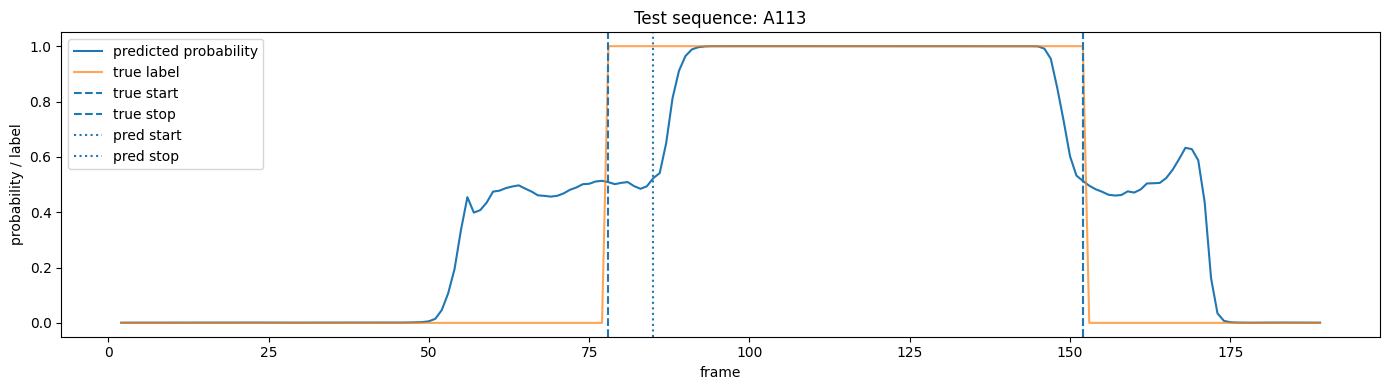

In [49]:
example_test_sequence_id = sequence_eval_ranked.sort_values("total_abs_boundary_error").iloc[0]["sequence_id"]
plot_seq_df = test_pred_df[test_pred_df["sequence_id"] == example_test_sequence_id].copy()
plot_seq_df = plot_seq_df.sort_values("frame_ref")

true_start = int(plot_seq_df["start_frame"].iloc[0])
true_stop = int(plot_seq_df["stop_frame"].iloc[0])
pred_start, pred_stop = longest_positive_run(plot_seq_df, pred_col="pred")

plt.figure(figsize=(14, 4))
plt.plot(plot_seq_df["frame_ref"], plot_seq_df["prob"], label="predicted probability")
plt.plot(plot_seq_df["frame_ref"], plot_seq_df["label"], label="true label", alpha=0.7)

plt.axvline(true_start, linestyle="--", label="true start")
plt.axvline(true_stop, linestyle="--", label="true stop")

if pred_start is not None:
    plt.axvline(pred_start, linestyle=":", label="pred start")
if pred_stop is not None:
    plt.axvline(pred_stop, linestyle=":", label="pred stop")

plt.title(f"Test sequence: {example_test_sequence_id}")
plt.xlabel("frame")
plt.ylabel("probability / label")
plt.legend()
plt.tight_layout()
plt.show()

### Save artifacts

In [50]:
test_pred_path = output_dir / "a11_problem_b_test_predictions.csv"
sequence_eval_path = output_dir / "a11_problem_b_sequence_eval.csv"
sequence_eval_summary_path = output_dir / "a11_problem_b_sequence_eval_summary.csv"
history_path = output_dir / "a11_problem_b_champion_history.csv"

test_pred_df.to_csv(test_pred_path, index=False)
sequence_eval_df.to_csv(sequence_eval_path, index=False)
sequence_eval_summary.to_csv(sequence_eval_summary_path, index=False)
champion_history_df.to_csv(history_path, index=False)

print("Saved:")
print(test_pred_path)
print(sequence_eval_path)
print(sequence_eval_summary_path)
print(history_path)

Saved:
reporting\results\a11_problem_b_test_predictions.csv
reporting\results\a11_problem_b_sequence_eval.csv
reporting\results\a11_problem_b_sequence_eval_summary.csv
reporting\results\a11_problem_b_champion_history.csv


### Log champion run to MLflow

In [51]:
with mlflow.start_run(run_name="problem_b_quick_champion_test_eval"):
    mlflow.log_param("problem", "B")
    mlflow.log_param("task", "inside_exercise_vs_outside_exercise")
    mlflow.log_param("feature_set", CHAMPION_CONFIG["feature_set"])
    mlflow.log_param("seq_len", CHAMPION_CONFIG["seq_len"])
    mlflow.log_param("hidden_dims", str(CHAMPION_CONFIG["hidden_dims"]))
    mlflow.log_param("dropout", CHAMPION_CONFIG["dropout"])
    mlflow.log_param("optimizer", CHAMPION_CONFIG["optimizer"])
    mlflow.log_param("batch_size", CHAMPION_CONFIG["batch_size"])
    mlflow.log_param("epochs", CHAMPION_CONFIG["epochs"])
    mlflow.log_param("patience", CHAMPION_CONFIG["patience"])
    mlflow.log_param("threshold", CHAMPION_CONFIG["threshold"])
    mlflow.log_param("learning_rate", LEARNING_RATE)
    mlflow.log_param("n_train_sequences", len(train_sequence_ids))
    mlflow.log_param("n_test_sequences", len(test_sequence_ids))
    mlflow.log_param("n_train_windows", int(len(y_train_all)))
    mlflow.log_param("n_test_windows", int(len(y_test)))

    mlflow.log_metric("test_precision", float(test_precision))
    mlflow.log_metric("test_recall", float(test_recall))
    mlflow.log_metric("test_f1_binary", float(test_f1))
    mlflow.log_metric("test_f1_macro", float(test_f1_macro))
    mlflow.log_metric("test_f1_weighted", float(test_f1_weighted))
    mlflow.log_metric("test_detection_rate", float(sequence_eval_df["detected_segment"].mean()))
    mlflow.log_metric("test_mean_abs_start_error_frames", float(sequence_eval_df["abs_start_error_frames"].mean()))
    mlflow.log_metric("test_mean_abs_stop_error_frames", float(sequence_eval_df["abs_stop_error_frames"].mean()))
    mlflow.log_metric("test_median_abs_start_error_frames", float(sequence_eval_df["abs_start_error_frames"].median()))
    mlflow.log_metric("test_median_abs_stop_error_frames", float(sequence_eval_df["abs_stop_error_frames"].median()))

    mlflow.log_artifact(str(test_pred_path))
    mlflow.log_artifact(str(sequence_eval_path))
    mlflow.log_artifact(str(sequence_eval_summary_path))
    mlflow.log_artifact(str(history_path))

    mlflow.pytorch.log_model(champion_model, artifact_path="model")

print("MLflow logging complete.")

2026/04/28 23:40:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/28 23:40:30 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is to set 'export_model' to True to save the pytorch model using the safe graph model format.
2026/04/28 23:40:30 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/04/28 23:40:37 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). ML

🏃 View run problem_b_quick_champion_test_eval at: https://172.27.62.170:5001/#/experiments/29/runs/3dbe1d5c67bd46759ae3e1a84ac3bbab
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/29
MLflow logging complete.


### Compact result summary for the report

In [52]:
report_summary = pd.DataFrame({
    "metric": [
        "test_precision",
        "test_recall",
        "test_f1_binary",
        "test_f1_macro",
        "test_f1_weighted",
        "test_detection_rate",
        "mean_abs_start_error_frames",
        "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",
        "median_abs_stop_error_frames",
    ],
    "value": [
        test_precision,
        test_recall,
        test_f1,
        test_f1_macro,
        test_f1_weighted,
        float(sequence_eval_df["detected_segment"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].median()),
        float(sequence_eval_df["abs_stop_error_frames"].mean()),
        float(sequence_eval_df["abs_stop_error_frames"].median()),
    ]
})

display(report_summary)

,metric,value
0,test_precision,0.909131
1,test_recall,0.873636
2,test_f1_binary,0.891030
3,test_f1_macro,0.856560
4,test_f1_weighted,0.865695
5,test_detection_rate,1.000000
6,mean_abs_start_error_frames,19.222222
7,median_abs_start_error_frames,8.000000
8,mean_abs_stop_error_frames,9.888889
9,median_abs_stop_error_frames,10.500000


### Define a focused longer training search around the winner

In [53]:
FINAL_FEATURE_SET_NAMES = ["coords_only"]
FINAL_SEQ_LENS = [3, 5, 9]
FINAL_HIDDEN_CONFIGS = [
    (128, 64),
    (256, 128),
]
FINAL_DROPOUTS = [0.1, 0.2, 0.3]
FINAL_OPTIMIZERS = ["adam", "adamw"]

FINAL_BATCH_SIZE = 32
FINAL_EPOCHS = 50
FINAL_PATIENCE = 8
FINAL_THRESHOLD = 0.5
FINAL_STRIDE = 1

### Focused CV search function

In [54]:
def run_final_cv_search():
    results = []

    for feature_set_name in FINAL_FEATURE_SET_NAMES:
        for seq_len in FINAL_SEQ_LENS:
            print(f"\n=== FINAL SEARCH | feature_set={feature_set_name} | seq_len={seq_len} ===")

            X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = prepare_train_test_arrays(
                feature_set_name=feature_set_name,
                seq_len=seq_len,
            )

            X_train_all_flat = flatten_if_needed(X_train_all)
            groups = meta_train["sequence_id"].values
            unique_train_sequences = np.unique(groups)
            n_splits_here = min(N_SPLITS, len(unique_train_sequences))

            if n_splits_here < 2:
                print("Skipping: not enough train sequences.")
                continue

            gkf = GroupKFold(n_splits=n_splits_here)

            for hidden_dims in FINAL_HIDDEN_CONFIGS:
                for dropout in FINAL_DROPOUTS:
                    for optimizer_name in FINAL_OPTIMIZERS:
                        fold_rows = []

                        for fold, (train_idx, val_idx) in enumerate(
                            gkf.split(X_train_all_flat, y_train_all, groups=groups),
                            start=1,
                        ):
                            fold_result = run_one_fold(
                                X_train_all_flat=X_train_all_flat,
                                y_train_all=y_train_all,
                                meta_train=meta_train,
                                train_idx=train_idx,
                                val_idx=val_idx,
                                hidden_dims=hidden_dims,
                                dropout=dropout,
                                optimizer_name=optimizer_name,
                                batch_size=FINAL_BATCH_SIZE,
                                epochs=FINAL_EPOCHS,
                                patience=FINAL_PATIENCE,
                                threshold=FINAL_THRESHOLD,
                            )

                            row = {
                                "feature_set": feature_set_name,
                                "seq_len": seq_len,
                                "hidden_dims": str(hidden_dims),
                                "dropout": dropout,
                                "optimizer": optimizer_name,
                                "fold": fold,
                                "val_precision": fold_result["precision"],
                                "val_recall": fold_result["recall"],
                                "val_f1": fold_result["f1"],
                                "val_loss": fold_result["loss"],
                            }
                            fold_rows.append(row)
                            results.append(row)

                        fold_df = pd.DataFrame(fold_rows)
                        print(
                            f"hidden={hidden_dims}, dropout={dropout}, opt={optimizer_name} | "
                            f"mean_f1={fold_df['val_f1'].mean():.4f}, "
                            f"mean_precision={fold_df['val_precision'].mean():.4f}, "
                            f"mean_recall={fold_df['val_recall'].mean():.4f}"
                        )

    return pd.DataFrame(results)

### Run the focused final search

In [55]:
final_results_df = run_final_cv_search()
print("Finished final search. Rows:", len(final_results_df))
display(final_results_df.head())


=== FINAL SEARCH | feature_set=coords_only | seq_len=3 ===
Epoch 001 | train_loss=0.2126 | val_loss=0.2420 | precision=0.9313 | recall=0.7054 | f1=0.8027
Epoch 010 | train_loss=0.1392 | val_loss=0.2004 | precision=0.9133 | recall=0.8814 | f1=0.8971
Early stopping at epoch 11
Epoch 001 | train_loss=0.2127 | val_loss=0.2148 | precision=0.9129 | recall=0.7785 | f1=0.8404
Epoch 010 | train_loss=0.1418 | val_loss=0.1884 | precision=0.9094 | recall=0.8543 | f1=0.8810
Early stopping at epoch 13
Epoch 001 | train_loss=0.2141 | val_loss=0.2351 | precision=0.9617 | recall=0.8390 | f1=0.8962
Epoch 010 | train_loss=0.1419 | val_loss=0.3454 | precision=0.9367 | recall=0.8801 | f1=0.9075
Early stopping at epoch 10
Epoch 001 | train_loss=0.2108 | val_loss=0.2523 | precision=0.9043 | recall=0.8596 | f1=0.8814
Early stopping at epoch 9
Epoch 001 | train_loss=0.2089 | val_loss=0.1592 | precision=0.9369 | recall=0.8029 | f1=0.8647
Epoch 010 | train_loss=0.1385 | val_loss=0.1697 | precision=0.9282 | reca

,feature_set,seq_len,hidden_dims,dropout,optimizer,fold,val_precision,val_recall,val_f1,val_loss
0,coords_only,3,"(128, 64)",0.1,adam,1,0.908745,0.895131,0.901887,0.192474
1,coords_only,3,"(128, 64)",0.1,adam,2,0.912216,0.848917,0.879429,0.169074
2,coords_only,3,"(128, 64)",0.1,adam,3,0.947173,0.875000,0.909657,0.223015
3,coords_only,3,"(128, 64)",0.1,adam,4,0.904321,0.859598,0.881392,0.252281
4,coords_only,3,"(128, 64)",0.1,adam,5,0.925186,0.894533,0.909601,0.135626


### Summarize the focused final search

In [56]:
final_summary_df = (
    final_results_df
    .groupby(["feature_set", "seq_len", "hidden_dims", "dropout", "optimizer"], as_index=False)
    .agg(
        mean_val_precision=("val_precision", "mean"),
        std_val_precision=("val_precision", "std"),
        mean_val_recall=("val_recall", "mean"),
        std_val_recall=("val_recall", "std"),
        mean_val_f1=("val_f1", "mean"),
        std_val_f1=("val_f1", "std"),
        mean_val_loss=("val_loss", "mean"),
    )
    .sort_values(["mean_val_f1", "mean_val_precision", "mean_val_recall"], ascending=[False, False, False])
    .reset_index(drop=True)
)

display(final_summary_df)

,feature_set,seq_len,hidden_dims,dropout,optimizer,mean_val_precision,std_val_precision,mean_val_recall,std_val_recall,mean_val_f1,std_val_f1,mean_val_loss
0,coords_only,9,"(256, 128)",0.2,adamw,0.915606,0.022091,0.904524,0.029097,0.909598,0.015071,0.181138
1,coords_only,9,"(256, 128)",0.3,adam,0.908267,0.018635,0.910619,0.022004,0.909195,0.013114,0.179753
2,coords_only,9,"(128, 64)",0.3,adamw,0.912514,0.021586,0.903412,0.042044,0.907274,0.022166,0.181650
3,coords_only,9,"(256, 128)",0.3,adamw,0.914693,0.020501,0.898911,0.039415,0.906147,0.020730,0.179672
4,coords_only,9,"(128, 64)",0.3,adam,0.920585,0.018115,0.886664,0.035245,0.902933,0.021293,0.179829
5,coords_only,9,"(128, 64)",0.2,adamw,0.923130,0.025495,0.884356,0.035558,0.902741,0.019664,0.179650
6,coords_only,9,"(256, 128)",0.1,adamw,0.928095,0.024921,0.879495,0.033615,0.902588,0.018486,0.186104
7,coords_only,9,"(256, 128)",0.2,adam,0.919388,0.024574,0.886682,0.029890,0.902411,0.020417,0.185516
8,coords_only,9,"(128, 64)",0.1,adamw,0.915092,0.026053,0.890866,0.036354,0.902080,0.016676,0.187141
9,coords_only,9,"(256, 128)",0.1,adam,0.917242,0.025844,0.890394,0.063848,0.901731,0.026615,0.185876


### Save the focused final search

In [57]:
final_results_path = output_dir / "a11_problem_b_final_cv_results.csv"
final_summary_path = output_dir / "a11_problem_b_final_cv_summary.csv"

final_results_df.to_csv(final_results_path, index=False)
final_summary_df.to_csv(final_summary_path, index=False)

print("Saved:")
print(final_results_path)
print(final_summary_path)

Saved:
reporting\results\a11_problem_b_final_cv_results.csv
reporting\results\a11_problem_b_final_cv_summary.csv


### Pick the final champion from the focused search

In [58]:
best_row = final_summary_df.iloc[0].to_dict()
best_row

{'feature_set': 'coords_only',
 'seq_len': 9,
 'hidden_dims': '(256, 128)',
 'dropout': 0.2,
 'optimizer': 'adamw',
 'mean_val_precision': 0.9156055342656211,
 'std_val_precision': 0.022091323261902655,
 'mean_val_recall': 0.9045238944560863,
 'std_val_recall': 0.029096811995785683,
 'mean_val_f1': 0.909597979122538,
 'std_val_f1': 0.015071231286421695,
 'mean_val_loss': 0.1811377671843345}

### Build final champion config from best row

In [59]:
FINAL_CHAMPION_CONFIG = {
    "feature_set": best_row["feature_set"],
    "seq_len": int(best_row["seq_len"]),
    "hidden_dims": tuple(int(x.strip()) for x in best_row["hidden_dims"].strip("()").split(",") if x.strip()),
    "dropout": float(best_row["dropout"]),
    "optimizer": best_row["optimizer"],
    "batch_size": 32,
    "epochs": 80,
    "patience": 12,
    "threshold": 0.5,
}

FINAL_CHAMPION_CONFIG

{'feature_set': 'coords_only',
 'seq_len': 9,
 'hidden_dims': (256, 128),
 'dropout': 0.2,
 'optimizer': 'adamw',
 'batch_size': 32,
 'epochs': 80,
 'patience': 12,
 'threshold': 0.5}

### Prepare arrays for the final champion

In [60]:
X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = prepare_train_test_arrays(
    feature_set_name=FINAL_CHAMPION_CONFIG["feature_set"],
    seq_len=FINAL_CHAMPION_CONFIG["seq_len"],
)

X_train_all_flat = flatten_if_needed(X_train_all)
X_test_flat = flatten_if_needed(X_test)

final_scaler = StandardScaler()
X_train_all_scaled = final_scaler.fit_transform(X_train_all_flat)
X_test_scaled = final_scaler.transform(X_test_flat)

n_pos_train = int(y_train_all.sum())
n_neg_train = int(len(y_train_all) - n_pos_train)
final_pos_weight_value = n_neg_train / max(n_pos_train, 1)
final_pos_weight_tensor = torch.tensor([final_pos_weight_value], dtype=torch.float32, device=DEVICE)

print("Train windows:", X_train_all_scaled.shape, y_train_all.shape)
print("Test windows:", X_test_scaled.shape, y_test.shape)
print("Final pos_weight:", final_pos_weight_value)

Train windows: (32877, 234) (32877,)
Test windows: (3694, 234) (3694,)
Final pos_weight: 0.5350172751890933


### Validation split for early stopping

In [61]:
train_seq_ids_sorted = sorted(meta_train["sequence_id"].unique())

seq_train_ids_sub, seq_val_ids_sub = train_test_split(
    train_seq_ids_sorted,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
)

seq_train_ids_sub = set(seq_train_ids_sub)
seq_val_ids_sub = set(seq_val_ids_sub)

train_mask_sub = meta_train["sequence_id"].isin(seq_train_ids_sub).values
val_mask_sub = meta_train["sequence_id"].isin(seq_val_ids_sub).values

X_train_sub = X_train_all_scaled[train_mask_sub]
y_train_sub = y_train_all[train_mask_sub]
X_val_sub = X_train_all_scaled[val_mask_sub]
y_val_sub = y_train_all[val_mask_sub]

print("Final sub-train:", X_train_sub.shape, y_train_sub.shape)
print("Final sub-val:", X_val_sub.shape, y_val_sub.shape)

Final sub-train: (29365, 234) (29365,)
Final sub-val: (3512, 234) (3512,)


### Train the final champion

In [62]:
train_dataset_sub = FrameWindowDataset(X_train_sub, y_train_sub)
val_dataset_sub = FrameWindowDataset(X_val_sub, y_val_sub)

train_loader_sub = DataLoader(
    train_dataset_sub,
    batch_size=FINAL_CHAMPION_CONFIG["batch_size"],
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)
val_loader_sub = DataLoader(
    val_dataset_sub,
    batch_size=FINAL_CHAMPION_CONFIG["batch_size"],
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

final_champion_model = DenseBinaryClassifier(
    input_dim=X_train_all_scaled.shape[1],
    hidden_dims=FINAL_CHAMPION_CONFIG["hidden_dims"],
    dropout=FINAL_CHAMPION_CONFIG["dropout"],
).to(DEVICE)

final_champion_model, final_history_df = train_binary_classifier(
    final_champion_model,
    train_loader_sub,
    val_loader_sub,
    optimizer_name=FINAL_CHAMPION_CONFIG["optimizer"],
    learning_rate=LEARNING_RATE,
    epochs=FINAL_CHAMPION_CONFIG["epochs"],
    patience=FINAL_CHAMPION_CONFIG["patience"],
    pos_weight=final_pos_weight_tensor,
    threshold=FINAL_CHAMPION_CONFIG["threshold"],
)

display(final_history_df.tail())

Epoch 001 | train_loss=0.1969 | val_loss=0.2126 | precision=0.9190 | recall=0.8426 | f1=0.8791
Epoch 010 | train_loss=0.1186 | val_loss=0.2134 | precision=0.9329 | recall=0.8481 | f1=0.8885
Epoch 020 | train_loss=0.0979 | val_loss=0.2392 | precision=0.9445 | recall=0.8648 | f1=0.9029
Early stopping at epoch 20


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
15,16,0.103762,0.194610,0.929923,0.922782,0.926338
16,17,0.100986,0.264671,0.912045,0.898038,0.904987
17,18,0.101312,0.191293,0.927042,0.905290,0.916037
18,19,0.099482,0.292393,0.910273,0.895904,0.903032
19,20,0.097869,0.239205,0.944548,0.864761,0.902895


### Evaluate the final champion on independent test data

In [63]:
final_champion_model.eval()

with torch.no_grad():
    final_test_logits = final_champion_model(
        torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE)
    )
    final_test_probs = torch.sigmoid(final_test_logits).cpu().numpy()
    final_test_preds = (final_test_probs >= FINAL_CHAMPION_CONFIG["threshold"]).astype(int)

final_test_pred_df = meta_test.copy()
final_test_pred_df["prob"] = final_test_probs
final_test_pred_df["pred"] = final_test_preds
final_test_pred_df["label"] = y_test.astype(int)

final_test_precision = precision_score(final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0)
final_test_recall = recall_score(final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0)
final_test_f1 = f1_score(final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0)
final_test_f1_macro = f1_score(final_test_pred_df["label"], final_test_pred_df["pred"], average="macro", zero_division=0)
final_test_f1_weighted = f1_score(final_test_pred_df["label"], final_test_pred_df["pred"], average="weighted", zero_division=0)
final_test_cm = confusion_matrix(final_test_pred_df["label"], final_test_pred_df["pred"])

print("Final independent test metrics")
print("precision:", final_test_precision)
print("recall:", final_test_recall)
print("f1 (binary, class=1):", final_test_f1)
print("f1_macro:", final_test_f1_macro)
print("f1_weighted:", final_test_f1_weighted)
print("\nConfusion matrix:")
print(final_test_cm)
print("\nClassification report:")
print(classification_report(final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0))

Final independent test metrics
precision: 0.9311282283642954
recall: 0.8663575042158516
f1 (binary, class=1): 0.8975758899322996
f1_macro: 0.8653062788928141
f1_weighted: 0.87447874548498

Confusion matrix:
[[1170  152]
 [ 317 2055]]

Classification report:
              precision    recall  f1-score   support

           0       0.79      0.89      0.83      1322
           1       0.93      0.87      0.90      2372

    accuracy                           0.87      3694
   macro avg       0.86      0.88      0.87      3694
weighted avg       0.88      0.87      0.87      3694



### Final boundary evaluation

In [64]:
final_sequence_rows = []

for sequence_id, seq_df in final_test_pred_df.groupby("sequence_id"):
    seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop = int(seq_df["stop_frame"].iloc[0])

    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    if pred_start is None or pred_stop is None:
        start_error = np.nan
        stop_error = np.nan
        abs_start_error = np.nan
        abs_stop_error = np.nan
        detected = 0
    else:
        start_error = pred_start - true_start
        stop_error = pred_stop - true_stop
        abs_start_error = abs(start_error)
        abs_stop_error = abs(stop_error)
        detected = 1

    final_sequence_rows.append({
        "sequence_id": sequence_id,
        "true_start": true_start,
        "true_stop": true_stop,
        "pred_start": pred_start,
        "pred_stop": pred_stop,
        "start_error_frames": start_error,
        "stop_error_frames": stop_error,
        "abs_start_error_frames": abs_start_error,
        "abs_stop_error_frames": abs_stop_error,
        "detected_segment": detected,
    })

final_sequence_eval_df = pd.DataFrame(final_sequence_rows)

final_sequence_eval_summary = pd.DataFrame({
    "metric": [
        "n_test_sequences",
        "n_detected_segments",
        "detection_rate",
        "mean_abs_start_error_frames",
        "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",
        "median_abs_stop_error_frames",
    ],
    "value": [
        len(final_sequence_eval_df),
        int(final_sequence_eval_df["detected_segment"].sum()),
        float(final_sequence_eval_df["detected_segment"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].median()),
        float(final_sequence_eval_df["abs_stop_error_frames"].mean()),
        float(final_sequence_eval_df["abs_stop_error_frames"].median()),
    ],
})

display(final_sequence_eval_summary)

,metric,value
0,n_test_sequences,18.000000
1,n_detected_segments,18.000000
2,detection_rate,1.000000
3,mean_abs_start_error_frames,19.055556
4,median_abs_start_error_frames,9.500000
5,mean_abs_stop_error_frames,10.611111
6,median_abs_stop_error_frames,10.000000


In [65]:
import mlflow.pyfunc


class ExerciseSegmentPredictor(mlflow.pyfunc.PythonModel):
    def __init__(self, model, scaler, feature_cols, seq_len, stride=1, threshold=0.5, device="cpu"):
        self.model = model
        self.scaler = scaler
        self.feature_cols = feature_cols
        self.seq_len = seq_len
        self.stride = stride
        self.threshold = threshold
        self.device = device
        self.movenet_to_assignment = {
            "nose": "head",
            "left_shoulder": "left_shoulder",
            "left_elbow": "left_elbow",
            "right_shoulder": "right_shoulder",
            "right_elbow": "right_elbow",
            "left_wrist": "left_hand",
            "right_wrist": "right_hand",
            "left_hip": "left_hip",
            "right_hip": "right_hip",
            "left_knee": "left_knee",
            "right_knee": "right_knee",
            "left_ankle": "left_foot",
            "right_ankle": "right_foot",
        }
        self.joints_13 = [
            "head",
            "left_shoulder",
            "left_elbow",
            "right_shoulder",
            "right_elbow",
            "left_hand",
            "right_hand",
            "left_hip",
            "right_hip",
            "left_knee",
            "right_knee",
            "left_foot",
            "right_foot",
        ]

    def _make_windows(self, df):
        df = df.sort_values("frame_index").reset_index(drop=True)

        values = df[self.feature_cols].to_numpy(dtype=np.float32)
        frame_ids = df["frame_index"].to_numpy(dtype=np.int32)

        X_list = []
        frame_ref_list = []

        for start in range(0, len(df) - self.seq_len + 1, self.stride):
            end = start + self.seq_len
            center_idx = start + self.seq_len // 2

            X_list.append(values[start:end])
            frame_ref_list.append(frame_ids[center_idx])

        X = np.stack(X_list).astype(np.float32)
        frame_refs = np.array(frame_ref_list, dtype=np.int32)

        return X, frame_refs
    
    def _add_normalized_coordinates(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Normalize x and y coordinates per frame using hip center and torso size.
        This reduces sensitivity to camera position / body translation / scale.
        """
        out = df.copy()

        out["hip_center_x"] = (out["left_hip_x"] + out["right_hip_x"]) / 2.0
        out["hip_center_y"] = (out["left_hip_y"] + out["right_hip_y"]) / 2.0

        out["shoulder_center_x"] = (out["left_shoulder_x"] + out["right_shoulder_x"]) / 2.0
        out["shoulder_center_y"] = (out["left_shoulder_y"] + out["right_shoulder_y"]) / 2.0

        torso_dx = out["shoulder_center_x"] - out["hip_center_x"]
        torso_dy = out["shoulder_center_y"] - out["hip_center_y"]
        out["torso_size"] = np.sqrt(torso_dx**2 + torso_dy**2)

        # avoid division by zero
        out["torso_size"] = out["torso_size"].replace(0, np.nan)
        out["torso_size"] = out["torso_size"].fillna(out["torso_size"].median())
        out["torso_size"] = out["torso_size"].clip(lower=1e-6)

        for joint in self.joints_13:
            out[f"{joint}_x_norm"] = (out[f"{joint}_x"] - out["hip_center_x"]) / out["torso_size"]
            out[f"{joint}_y_norm"] = (out[f"{joint}_y"] - out["hip_center_y"]) / out["torso_size"]

        return out
    

    def _add_selected_distances(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Add a small set of normalized distances that are likely useful for squat detection.
        """
        out = df.copy()

        def dist(j1, j2, name):
            dx = out[f"{j1}_x_norm"] - out[f"{j2}_x_norm"]
            dy = out[f"{j1}_y_norm"] - out[f"{j2}_y_norm"]
            out[name] = np.sqrt(dx**2 + dy**2)

        dist("left_hip", "left_knee", "dist_left_hip_knee")
        dist("right_hip", "right_knee", "dist_right_hip_knee")
        dist("left_knee", "left_foot", "dist_left_knee_foot")
        dist("right_knee", "right_foot", "dist_right_knee_foot")
        dist("head", "left_hip", "dist_head_left_hip")
        dist("head", "right_hip", "dist_head_right_hip")
        dist("left_hand", "left_knee", "dist_left_hand_left_knee")
        dist("right_hand", "right_knee", "dist_right_hand_right_knee")
        dist("left_hip", "right_hip", "dist_hip_width")
        dist("left_shoulder", "right_shoulder", "dist_shoulder_width")

        return out
    

    def _add_selected_angles(self,df: pd.DataFrame) -> pd.DataFrame:
        """
        Add a few joint angles in 2D.
        Angle at point b from vectors ba and bc.
        """
        out = df.copy()

        def angle(a, b, c, name):
            bax = out[f"{a}_x_norm"] - out[f"{b}_x_norm"]
            bay = out[f"{a}_y_norm"] - out[f"{b}_y_norm"]
            bcx = out[f"{c}_x_norm"] - out[f"{b}_x_norm"]
            bcy = out[f"{c}_y_norm"] - out[f"{b}_y_norm"]

            dot = bax * bcx + bay * bcy
            norm1 = np.sqrt(bax**2 + bay**2)
            norm2 = np.sqrt(bcx**2 + bcy**2)
            denom = (norm1 * norm2).clip(lower=1e-6)

            cos_val = np.clip(dot / denom, -1.0, 1.0)
            out[name] = np.arccos(cos_val)

        angle("left_shoulder", "left_hip", "left_knee", "angle_left_hip")
        angle("right_shoulder", "right_hip", "right_knee", "angle_right_hip")
        angle("left_hip", "left_knee", "left_foot", "angle_left_knee")
        angle("right_hip", "right_knee", "right_foot", "angle_right_knee")
        angle("left_elbow", "left_shoulder", "left_hip", "angle_left_shoulder")
        angle("right_elbow", "right_shoulder", "right_hip", "angle_right_shoulder")

        return out
    

    def _add_simple_velocity_features(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Per-frame delta features for normalized coordinates.
        """
        out = df.copy()

        norm_cols = [f"{j}_{axis}_norm" for j in self.joints_13 for axis in ["x", "y"]]
        for col in norm_cols:
            out[f"{col}_vel"] = out[col].diff().fillna(0.0)

        return out

    def _add_features(self, df):
        out = df.copy()

        out = self._add_normalized_coordinates(out)
        out = self._add_selected_distances(out)
        out = self._add_selected_angles(out)
        out = self._add_simple_velocity_features(out)

        return out
    
    def _strip_columns(self, df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        df.columns = [c.strip() for c in df.columns]
        return df
    

    def _movenet_as_assignment(self, df: pd.DataFrame) -> pd.DataFrame:
        df = self._strip_columns(df)

        frame_col = "frame_index"
        if frame_col not in df.columns:
            raise ValueError("Missing required frame column: frame_index")

        out = pd.DataFrame()
        out["frame_index"] = df[frame_col].astype(int)

        if "sequence_id" in df.columns:
            out["sequence_id"] = df["sequence_id"].astype(str)

        if "timestamp_ms" in df.columns:
            out["timestamp_ms"] = df["timestamp_ms"]

        for movenet_joint, assignment_joint in self.movenet_to_assignment.items():
            for suffix in ["x", "y", "score"]:
                src = f"{movenet_joint}_{suffix}"
                dst = f"{assignment_joint}_{suffix}"
                if src not in df.columns:
                    raise ValueError(f"Missing expected MoveNet column: {src}")
                out[dst] = pd.to_numeric(df[src], errors="coerce")

        return out.sort_values("frame_index").reset_index(drop=True)
    

    def _longest_positive_run(self,frame_df: pd.DataFrame, pred_col: str = "pred") -> tuple[int | None, int | None]:
        """
        Returns the start and end frame of the longest consecutive predicted-positive run.
        If no positive run exists, returns (None, None).
        """
        frame_df = frame_df.sort_values("frame_ref").reset_index(drop=True)

        best_start = None
        best_end = None
        best_len = 0

        current_start = None
        current_end = None

        for _, row in frame_df.iterrows():
            frame_no = int(row["frame_ref"])
            is_pos = int(row[pred_col]) == 1

            if is_pos:
                if current_start is None:
                    current_start = frame_no
                    current_end = frame_no
                elif frame_no == current_end + 1:
                    current_end = frame_no
                else:
                    run_len = current_end - current_start + 1
                    if run_len > best_len:
                        best_len = run_len
                        best_start = current_start
                        best_end = current_end
                    current_start = frame_no
                    current_end = frame_no
            else:
                if current_start is not None:
                    run_len = current_end - current_start + 1
                    if run_len > best_len:
                        best_len = run_len
                        best_start = current_start
                        best_end = current_end
                    current_start = None
                    current_end = None

        if current_start is not None:
            run_len = current_end - current_start + 1
            if run_len > best_len:
                best_len = run_len
                best_start = current_start
                best_end = current_end

        return best_start, best_end

    def predict(self, context, model_input: pd.DataFrame) -> pd.DataFrame:
        df = model_input.copy()
        df = self._movenet_as_assignment(df)
        if "sequence_id" not in df.columns:
            df["sequence_id"] = "sequence_0"

        feat_df = self._add_features(df)

        rows = []

        self.model.to(self.device)
        self.model.eval()

        for sequence_id, seq_df in feat_df.groupby("sequence_id"):
            X, frame_refs = self._make_windows(seq_df)
            X_flat = X.reshape(X.shape[0], -1)
            X_scaled = self.scaler.transform(X_flat)

            with torch.no_grad():
                logits = self.model(
                    torch.tensor(X_scaled, dtype=torch.float32, device=self.device)
                )
                probs = torch.sigmoid(logits).cpu().numpy().reshape(-1)

            preds = (probs >= self.threshold).astype(int).reshape(-1)

            pred_df = pd.DataFrame({
                "sequence_id": sequence_id,
                "frame_ref": frame_refs,
                "prob": probs,
                "pred": preds,
            })

            pred_start, pred_stop = self._longest_positive_run(pred_df, pred_col="pred")

            pred_df["pred_start"] = pred_start
            pred_df["pred_stop"] = pred_stop

            rows.append(pred_df)

        return pd.concat(rows, ignore_index=True)


In [66]:
# Create model instance
final_wrapped_model = ExerciseSegmentPredictor(
    model=final_champion_model,
    scaler=final_scaler,
    feature_cols=FEATURE_SETS[FINAL_CHAMPION_CONFIG["feature_set"]],
    seq_len=FINAL_CHAMPION_CONFIG["seq_len"],
    stride=FINAL_STRIDE,
    threshold=FINAL_CHAMPION_CONFIG["threshold"],
    device="cpu",
)

In [67]:

# Load or create new input data
new_df = pd.read_csv("../../../data/processed/movenet/csv_output/A1.csv")

# Make sure the required feature columns exist
predictions = final_wrapped_model.predict(None, new_df)
predictions

,sequence_id,frame_ref,prob,pred,pred_start,pred_stop
0,sequence_0,4,4.226473e-04,0,75,172
1,sequence_0,5,4.422444e-04,0,75,172
2,sequence_0,6,5.086542e-04,0,75,172
3,sequence_0,7,4.022605e-04,0,75,172
4,sequence_0,8,3.442138e-04,0,75,172
...,...,...,...,...,...,...
216,sequence_0,220,4.235275e-13,0,75,172
217,sequence_0,221,3.759581e-13,0,75,172
218,sequence_0,222,2.513183e-13,0,75,172
219,sequence_0,223,1.984306e-13,0,75,172


### Log the final champion to MLflow

In [69]:
final_test_pred_path = output_dir / "a11_problem_b_final_test_predictions.csv"
final_sequence_eval_path = output_dir / "a11_problem_b_final_sequence_eval.csv"
final_sequence_eval_summary_path = output_dir / "a11_problem_b_final_sequence_eval_summary.csv"
final_history_path = output_dir / "a11_problem_b_final_history.csv"

final_test_pred_df.to_csv(final_test_pred_path, index=False)
final_sequence_eval_df.to_csv(final_sequence_eval_path, index=False)
final_sequence_eval_summary.to_csv(final_sequence_eval_summary_path, index=False)
final_history_df.to_csv(final_history_path, index=False)

with mlflow.start_run(run_name="problem_b_final_champion_test_eval"):
    for k, v in FINAL_CHAMPION_CONFIG.items():
        mlflow.log_param(k, str(v) if isinstance(v, tuple) else v)

    mlflow.log_param("problem", "B")
    mlflow.log_param("task", "inside_exercise_vs_outside_exercise")
    mlflow.log_param("learning_rate", LEARNING_RATE)
    mlflow.log_param("n_train_sequences", len(train_sequence_ids))
    mlflow.log_param("n_test_sequences", len(test_sequence_ids))
    mlflow.log_param("n_train_windows", int(len(y_train_all)))
    mlflow.log_param("n_test_windows", int(len(y_test)))

    mlflow.log_metric("test_precision", float(final_test_precision))
    mlflow.log_metric("test_recall", float(final_test_recall))
    mlflow.log_metric("test_f1_binary", float(final_test_f1))
    mlflow.log_metric("test_f1_macro", float(final_test_f1_macro))
    mlflow.log_metric("test_f1_weighted", float(final_test_f1_weighted))
    mlflow.log_metric("test_detection_rate", float(final_sequence_eval_df["detected_segment"].mean()))
    mlflow.log_metric("test_mean_abs_start_error_frames", float(final_sequence_eval_df["abs_start_error_frames"].mean()))
    mlflow.log_metric("test_mean_abs_stop_error_frames", float(final_sequence_eval_df["abs_stop_error_frames"].mean()))
    mlflow.log_metric("test_median_abs_start_error_frames", float(final_sequence_eval_df["abs_start_error_frames"].median()))
    mlflow.log_metric("test_median_abs_stop_error_frames", float(final_sequence_eval_df["abs_stop_error_frames"].median()))

    mlflow.log_artifact(str(final_test_pred_path))
    mlflow.log_artifact(str(final_sequence_eval_path))
    mlflow.log_artifact(str(final_sequence_eval_summary_path))
    mlflow.log_artifact(str(final_history_path))

    mlflow.pyfunc.log_model(
        name="model",
        python_model=final_wrapped_model,
        pip_requirements=[
            "mlflow",
            "numpy",
            "pandas",
            "torch",
            "scikit-learn",
        ],
    )

print("Final MLflow logging complete.")

2026/04/29 05:16:48 WARNING mlflow.pyfunc: Failed to infer model signature: Type hint <input: <class 'pandas.core.frame.DataFrame'>, output: <class 'pandas.core.frame.DataFrame'>> cannot be used to infer model signature and input example is not provided, model signature cannot be inferred.


🏃 View run problem_b_final_champion_test_eval at: https://172.27.62.170:5001/#/experiments/29/runs/8ed7e14daa304f3aa9537052c9bd7222
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/29
Final MLflow logging complete.


### Final compact summary table

In [70]:
final_report_summary = pd.DataFrame({
    "metric": [
        "test_precision",
        "test_recall",
        "test_f1_binary",
        "test_f1_macro",
        "test_f1_weighted",
        "test_detection_rate",
        "mean_abs_start_error_frames",
        "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",
        "median_abs_stop_error_frames",
    ],
    "value": [
        final_test_precision,
        final_test_recall,
        final_test_f1,
        final_test_f1_macro,
        final_test_f1_weighted,
        float(final_sequence_eval_df["detected_segment"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].median()),
        float(final_sequence_eval_df["abs_stop_error_frames"].mean()),
        float(final_sequence_eval_df["abs_stop_error_frames"].median()),
    ]
})

display(final_report_summary)

,metric,value
0,test_precision,0.931128
1,test_recall,0.866358
2,test_f1_binary,0.897576
3,test_f1_macro,0.865306
4,test_f1_weighted,0.874479
5,test_detection_rate,1.000000
6,mean_abs_start_error_frames,19.055556
7,median_abs_start_error_frames,9.500000
8,mean_abs_stop_error_frames,10.611111
9,median_abs_stop_error_frames,10.000000


### Analytic cell
Confusion matrix plot, Boundary error distribution, Per-sequence start/stop boundary errors, Plot best, median, and worst test sequence predictions

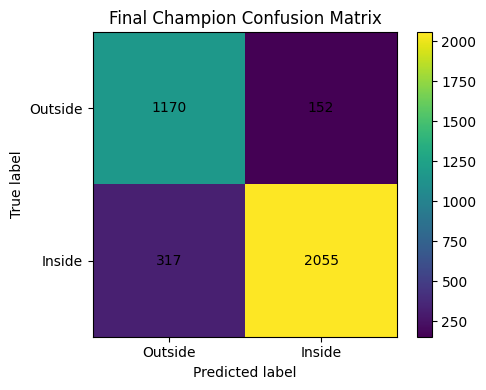

In [71]:
fig, ax = plt.subplots(figsize=(5, 4))

im = ax.imshow(final_test_cm)

ax.set_title("Final Champion Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Outside", "Inside"])
ax.set_yticklabels(["Outside", "Inside"])

for i in range(final_test_cm.shape[0]):
    for j in range(final_test_cm.shape[1]):
        ax.text(j, i, final_test_cm[i, j], ha="center", va="center")

plt.colorbar(im)
plt.tight_layout()
plt.show()

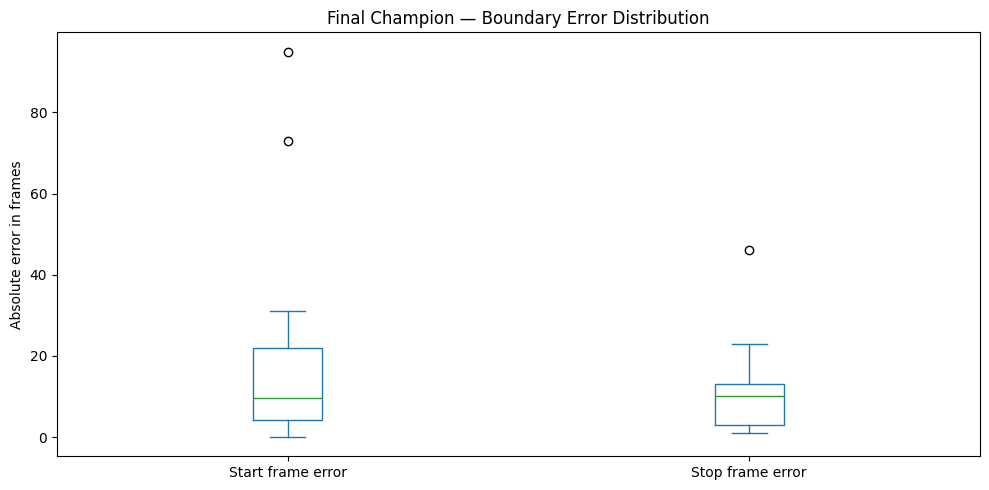

,start_error_abs,stop_error_abs
count,18.000000,18.000000
mean,19.055556,10.611111
std,25.565308,10.825563
min,0.000000,1.000000
25%,4.250000,3.000000
50%,9.500000,10.000000
75%,22.000000,13.000000
max,95.000000,46.000000


In [72]:
fig, ax = plt.subplots(figsize=(10, 5))

boundary_errors = pd.DataFrame({
    "start_error_abs": final_sequence_eval_df["abs_start_error_frames"],
    "stop_error_abs": final_sequence_eval_df["abs_stop_error_frames"],
})

boundary_errors.plot(kind="box", ax=ax)

ax.set_title("Final Champion — Boundary Error Distribution")
ax.set_ylabel("Absolute error in frames")
ax.set_xticklabels(["Start frame error", "Stop frame error"])

plt.tight_layout()
plt.show()

display(boundary_errors.describe())

,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
4,A138,69,286,164,275,95,-11,95,11,1,106
3,A121,0,218,73,236,73,18,73,18,1,91
12,A57,64,254,74,208,10,-46,10,46,1,56
15,A68,48,163,21,153,-27,-10,27,10,1,37
16,A95,35,179,4,175,-31,-4,31,4,1,35
2,A117,0,215,4,192,4,-23,4,23,1,27
5,A140,6,111,29,108,23,-3,23,3,1,26
1,A114,125,185,106,188,-19,3,19,3,1,22
7,A16,30,150,37,136,7,-14,7,14,1,21
6,A159,47,122,56,112,9,-10,9,10,1,19


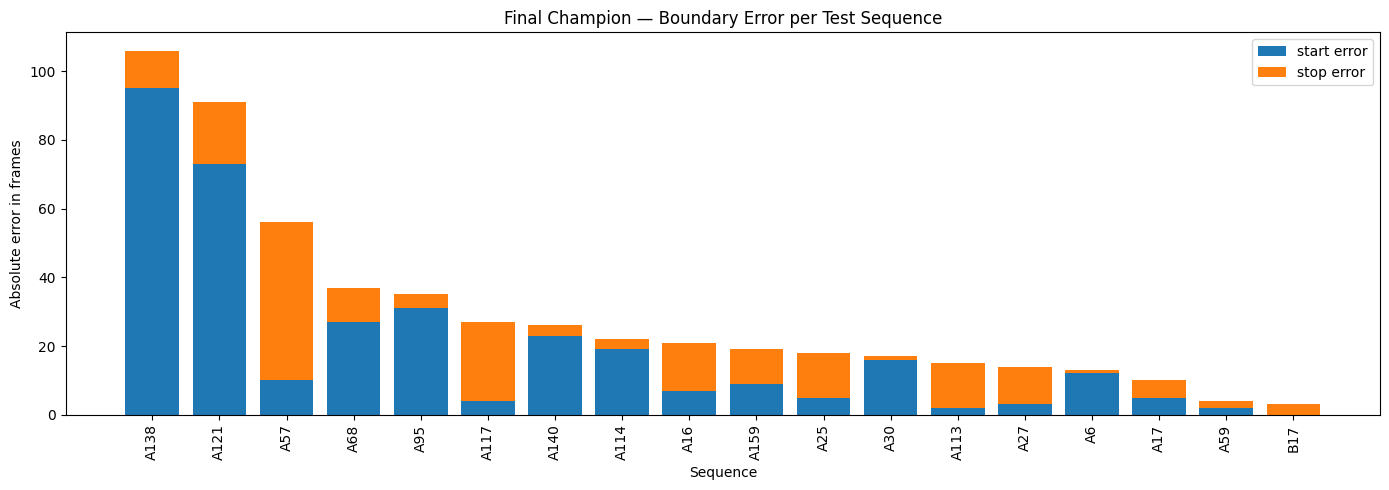

In [73]:
plot_boundary_df = final_sequence_eval_df.copy()
plot_boundary_df["total_abs_error"] = (
    plot_boundary_df["abs_start_error_frames"] +
    plot_boundary_df["abs_stop_error_frames"]
)

plot_boundary_df = plot_boundary_df.sort_values("total_abs_error", ascending=False)

display(plot_boundary_df)

plt.figure(figsize=(14, 5))
plt.bar(plot_boundary_df["sequence_id"], plot_boundary_df["abs_start_error_frames"], label="start error")
plt.bar(plot_boundary_df["sequence_id"], plot_boundary_df["abs_stop_error_frames"], bottom=plot_boundary_df["abs_start_error_frames"], label="stop error")

plt.title("Final Champion — Boundary Error per Test Sequence")
plt.xlabel("Sequence")
plt.ylabel("Absolute error in frames")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

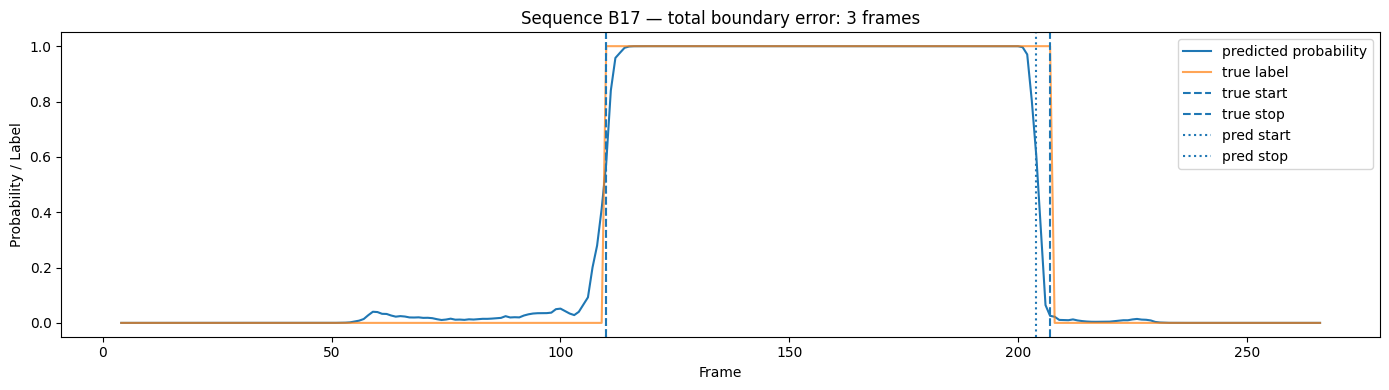

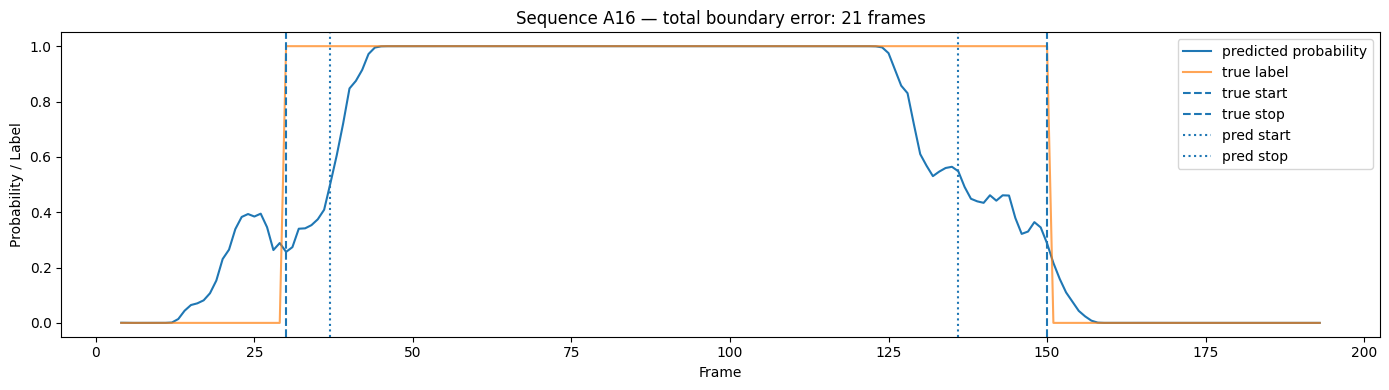

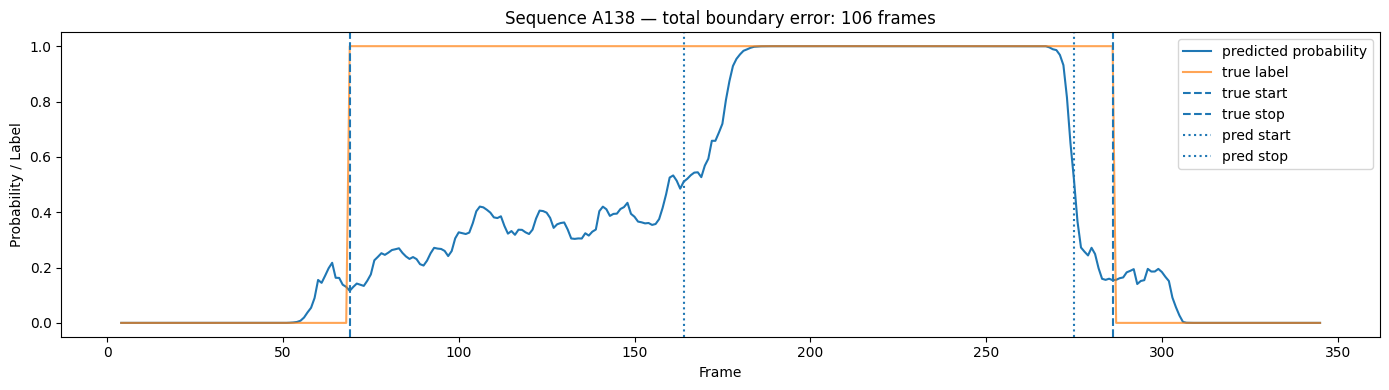

In [74]:
ranked_sequences = final_sequence_eval_df.copy()
ranked_sequences["total_abs_error"] = (
    ranked_sequences["abs_start_error_frames"] +
    ranked_sequences["abs_stop_error_frames"]
)

best_seq = ranked_sequences.sort_values("total_abs_error").iloc[0]["sequence_id"]
median_seq = ranked_sequences.sort_values("total_abs_error").iloc[len(ranked_sequences) // 2]["sequence_id"]
worst_seq = ranked_sequences.sort_values("total_abs_error", ascending=False).iloc[0]["sequence_id"]

for sequence_id in [best_seq, median_seq, worst_seq]:
    plot_seq_df = final_test_pred_df[final_test_pred_df["sequence_id"] == sequence_id].copy()
    plot_seq_df = plot_seq_df.sort_values("frame_ref")

    true_start = int(plot_seq_df["start_frame"].iloc[0])
    true_stop = int(plot_seq_df["stop_frame"].iloc[0])
    pred_start, pred_stop = longest_positive_run(plot_seq_df, pred_col="pred")

    plt.figure(figsize=(14, 4))
    plt.plot(plot_seq_df["frame_ref"], plot_seq_df["prob"], label="predicted probability")
    plt.plot(plot_seq_df["frame_ref"], plot_seq_df["label"], label="true label", alpha=0.7)

    plt.axvline(true_start, linestyle="--", label="true start")
    plt.axvline(true_stop, linestyle="--", label="true stop")

    if pred_start is not None:
        plt.axvline(pred_start, linestyle=":", label="pred start")
    if pred_stop is not None:
        plt.axvline(pred_stop, linestyle=":", label="pred stop")

    total_error = ranked_sequences.loc[
        ranked_sequences["sequence_id"] == sequence_id,
        "total_abs_error"
    ].iloc[0]

    plt.title(f"Sequence {sequence_id} — total boundary error: {total_error:.0f} frames")
    plt.xlabel("Frame")
    plt.ylabel("Probability / Label")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [77]:
# Final table: boundary predictions for ALL sequences
# Fixed version: makes sure model and input tensor are on the same device

ALL_FEATURE_COLS = FEATURE_SETS[FINAL_CHAMPION_CONFIG["feature_set"]]

X_all, y_all, meta_all = make_windows_for_all_sequences(
    all_feat_df,
    feature_cols=ALL_FEATURE_COLS,
    seq_len=FINAL_CHAMPION_CONFIG["seq_len"],
    stride=FINAL_STRIDE,
)

X_all_flat = flatten_if_needed(X_all)
X_all_scaled = final_scaler.transform(X_all_flat)

# IMPORTANT FIX:
# Use the actual device where the final champion model currently lives.
model_device = next(final_champion_model.parameters()).device
print("Final champion model device:", model_device)

final_champion_model.eval()

with torch.no_grad():
    X_all_tensor = torch.tensor(
        X_all_scaled,
        dtype=torch.float32,
        device=model_device,
    )

    all_logits = final_champion_model(X_all_tensor)
    all_probs = torch.sigmoid(all_logits).detach().cpu().numpy()
    all_preds = (all_probs >= FINAL_CHAMPION_CONFIG["threshold"]).astype(int)

all_pred_df = meta_all.copy()
all_pred_df["prob"] = all_probs
all_pred_df["pred"] = all_preds
all_pred_df["label"] = y_all.astype(int)

all_sequence_rows = []

for sequence_id, seq_df in all_pred_df.groupby("sequence_id"):
    seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop = int(seq_df["stop_frame"].iloc[0])

    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    if pred_start is None or pred_stop is None:
        start_error = np.nan
        stop_error = np.nan
        abs_start_error = np.nan
        abs_stop_error = np.nan
        detected = 0
    else:
        start_error = pred_start - true_start
        stop_error = pred_stop - true_stop
        abs_start_error = abs(start_error)
        abs_stop_error = abs(stop_error)
        detected = 1

    all_sequence_rows.append({
        "sequence_id": sequence_id,
        "true_start": true_start,
        "true_stop": true_stop,
        "pred_start": pred_start,
        "pred_stop": pred_stop,
        "start_error_frames": start_error,
        "stop_error_frames": stop_error,
        "abs_start_error_frames": abs_start_error,
        "abs_stop_error_frames": abs_stop_error,
        "detected_segment": detected,
    })

all_boundary_table = pd.DataFrame(all_sequence_rows)

all_boundary_table["total_abs_error"] = (
    all_boundary_table["abs_start_error_frames"].fillna(9999)
    + all_boundary_table["abs_stop_error_frames"].fillna(9999)
)

all_boundary_table = all_boundary_table[
    [
        "sequence_id",
        "true_start",
        "true_stop",
        "pred_start",
        "pred_stop",
        "start_error_frames",
        "stop_error_frames",
        "abs_start_error_frames",
        "abs_stop_error_frames",
        "detected_segment",
        "total_abs_error",
    ]
].sort_values("total_abs_error", ascending=False).reset_index(drop=True)

display(all_boundary_table)

all_boundary_table_path = output_dir / "a11_problem_b_all_boundary_table.csv"
all_boundary_table.to_csv(all_boundary_table_path, index=False)

print("Saved all-sequence boundary table to:")
print(all_boundary_table_path)

Final champion model device: cpu


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A86,4,261,96,219,92,-42,92,42,1,134
1,A138,69,286,164,275,95,-11,95,11,1,106
2,A81,22,302,97,285,75,-17,75,17,1,92
3,A121,0,218,73,236,73,18,73,18,1,91
4,A108,131,284,142,214,11,-70,11,70,1,81
...,...,...,...,...,...,...,...,...,...,...,...
174,B7,123,218,123,216,0,-2,0,2,1,2
175,A112,84,146,83,145,-1,-1,1,1,1,2
176,A39,43,100,43,101,0,1,0,1,1,1
177,A11,24,241,24,241,0,0,0,0,1,0


Saved all-sequence boundary table to:
reporting\results\a11_problem_b_all_boundary_table.csv


In [78]:
# Top 20 worst and best boundary predictions across ALL sequences

worst_20_boundary_predictions = (
    all_boundary_table
    .sort_values("total_abs_error", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

best_20_boundary_predictions = (
    all_boundary_table
    .sort_values("total_abs_error", ascending=True)
    .head(20)
    .reset_index(drop=True)
)

print("Top 20 worst boundary predictions:")
display(worst_20_boundary_predictions)

print("Top 20 best boundary predictions:")
display(best_20_boundary_predictions)

worst_20_path = output_dir / "a11_problem_b_worst_20_boundary_predictions.csv"
best_20_path = output_dir / "a11_problem_b_best_20_boundary_predictions.csv"

worst_20_boundary_predictions.to_csv(worst_20_path, index=False)
best_20_boundary_predictions.to_csv(best_20_path, index=False)

print("Saved:")
print(worst_20_path)
print(best_20_path)

Top 20 worst boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,A86,4,261,96,219,92,-42,92,42,1,134
1,A138,69,286,164,275,95,-11,95,11,1,106
2,A81,22,302,97,285,75,-17,75,17,1,92
3,A121,0,218,73,236,73,18,73,18,1,91
4,A108,131,284,142,214,11,-70,11,70,1,81
5,A88,1,258,30,213,29,-45,29,45,1,74
6,A87,3,219,22,170,19,-49,19,49,1,68
7,A52,21,173,47,133,26,-40,26,40,1,66
8,A133,0,175,15,125,15,-50,15,50,1,65
9,A130,1,236,38,257,37,21,37,21,1,58


Top 20 best boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
0,B10,108,193,108,193,0,0,0,0,1,0
1,A11,24,241,24,241,0,0,0,0,1,0
2,A39,43,100,43,101,0,1,0,1,1,1
3,A112,84,146,83,145,-1,-1,1,1,1,2
4,B7,123,218,123,216,0,-2,0,2,1,2
5,A100,3,165,4,166,1,1,1,1,1,2
6,B12,106,189,106,187,0,-2,0,2,1,2
7,A75,2,99,4,99,2,0,2,0,1,2
8,B15,111,203,109,203,-2,0,2,0,1,2
9,B18,108,196,109,194,1,-2,1,2,1,3


Saved:
reporting\results\a11_problem_b_worst_20_boundary_predictions.csv
reporting\results\a11_problem_b_best_20_boundary_predictions.csv


### Example usage: make predictions with the champion model
# 1) using the model trained in this notebook
# 2) optionally loading the champion model from MLflow

Using model device: cpu
Prediction using notebook-trained champion model:


,sequence_id,true_start,true_stop,pred_start,pred_stop,n_predicted_inside_frames,mean_probability,max_probability
0,A1,68,179,75,172,98,0.473173,1.0


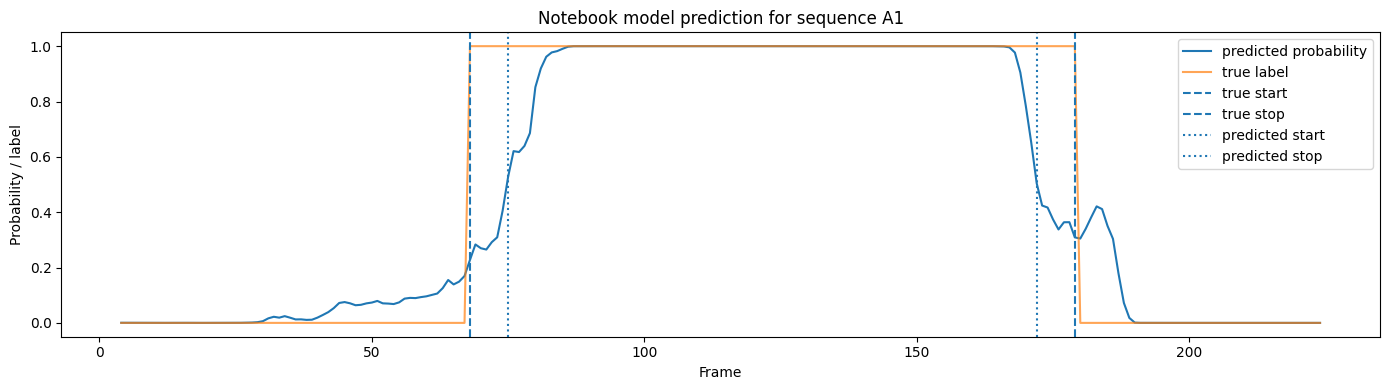

Using model device: cpu
Prediction using MLflow-loaded champion model:


,sequence_id,true_start,true_stop,pred_start,pred_stop,n_predicted_inside_frames,mean_probability,max_probability
0,A1,68,179,75,172,98,0.473173,1.0


In [81]:
# Example usage: make predictions with the champion model
# 1) using the model trained in this notebook
# 2) optionally loading the champion model from MLflow
#
# Fixed version:
# - Gets the model device inside the function
# - Sends the input tensor to the same device as that exact model
# - Avoids using a stale/global model_device variable

def predict_sequence_with_champion(model_to_use, sequence_id):
    sequence_df = all_feat_df[all_feat_df["sequence_id"] == sequence_id].copy()

    if sequence_df.empty:
        raise ValueError(f"No sequence found with sequence_id={sequence_id}")

    X_seq, y_seq, meta_seq = make_windows_for_all_sequences(
        sequence_df,
        feature_cols=FEATURE_SETS[FINAL_CHAMPION_CONFIG["feature_set"]],
        seq_len=FINAL_CHAMPION_CONFIG["seq_len"],
        stride=FINAL_STRIDE,
    )

    X_seq_flat = flatten_if_needed(X_seq)
    X_seq_scaled = final_scaler.transform(X_seq_flat)

    # IMPORTANT:
    # Get the actual device of THIS model.
    model_device = next(model_to_use.parameters()).device
    print("Using model device:", model_device)

    model_to_use.eval()

    with torch.no_grad():
        X_seq_tensor = torch.tensor(
            X_seq_scaled,
            dtype=torch.float32,
            device=model_device,
        )

        logits = model_to_use(X_seq_tensor)
        probs = torch.sigmoid(logits).detach().cpu().numpy()
        preds = (probs >= FINAL_CHAMPION_CONFIG["threshold"]).astype(int)

    pred_df = meta_seq.copy()
    pred_df["prob"] = probs
    pred_df["pred"] = preds
    pred_df["label"] = y_seq.astype(int)

    pred_start, pred_stop = longest_positive_run(pred_df, pred_col="pred")

    result = {
        "sequence_id": sequence_id,
        "true_start": int(pred_df["start_frame"].iloc[0]),
        "true_stop": int(pred_df["stop_frame"].iloc[0]),
        "pred_start": pred_start,
        "pred_stop": pred_stop,
        "n_predicted_inside_frames": int(pred_df["pred"].sum()),
        "mean_probability": float(pred_df["prob"].mean()),
        "max_probability": float(pred_df["prob"].max()),
    }

    return result, pred_df


example_sequence_id = sorted(all_feat_df["sequence_id"].unique())[0]

notebook_result, notebook_pred_df = predict_sequence_with_champion(
    model_to_use=final_champion_model,
    sequence_id=example_sequence_id,
)

print("Prediction using notebook-trained champion model:")
display(pd.DataFrame([notebook_result]))

plt.figure(figsize=(14, 4))
plt.plot(
    notebook_pred_df["frame_ref"],
    notebook_pred_df["prob"],
    label="predicted probability",
)
plt.plot(
    notebook_pred_df["frame_ref"],
    notebook_pred_df["label"],
    label="true label",
    alpha=0.7,
)

plt.axvline(notebook_result["true_start"], linestyle="--", label="true start")
plt.axvline(notebook_result["true_stop"], linestyle="--", label="true stop")

if notebook_result["pred_start"] is not None:
    plt.axvline(
        notebook_result["pred_start"],
        linestyle=":",
        label="predicted start",
    )

if notebook_result["pred_stop"] is not None:
    plt.axvline(
        notebook_result["pred_stop"],
        linestyle=":",
        label="predicted stop",
    )

plt.title(f"Notebook model prediction for sequence {example_sequence_id}")
plt.xlabel("Frame")
plt.ylabel("Probability / label")
plt.legend()
plt.tight_layout()
plt.show()


# Optional MLflow-loaded model example.
# Set this to None if you only want to use the model trained in the notebook.
MLFLOW_MODEL_URI = "runs:/bfcf7726d1cc4bc998adfb62299bd9cd/model"

if MLFLOW_MODEL_URI is not None:
    import mlflow.pytorch

    mlflow_model = mlflow.pytorch.load_model(MLFLOW_MODEL_URI)

    # Put the MLflow-loaded model on a clear device.
    # CPU is safest for this prediction/plotting cell.
    mlflow_model = mlflow_model.to("cpu")

    mlflow_result, mlflow_pred_df = predict_sequence_with_champion(
        model_to_use=mlflow_model,
        sequence_id=example_sequence_id,
    )

    print("Prediction using MLflow-loaded champion model:")
    display(pd.DataFrame([mlflow_result]))
else:
    print("MLflow example skipped. Set MLFLOW_MODEL_URI to load a saved MLflow model.")

### Corrected Kinect CSV evaluation

These cells compare the already trained champion model against the original Kinect labels and the manually corrected Kinect labels from `kinect_good_preprocessed_new`.

Important: this does not retrain the model. It only changes the ground-truth labels used for evaluation.

In [84]:
# Corrected Kinect evaluation helpers
# This evaluates the already trained final_champion_model against original and corrected labels.

def build_boundary_table(pred_df):
    rows = []

    for sequence_id, seq_df in pred_df.groupby("sequence_id"):
        seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

        true_start = int(seq_df["start_frame"].iloc[0])
        true_stop = int(seq_df["stop_frame"].iloc[0])

        pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

        if pred_start is None or pred_stop is None:
            detected = 0
            start_error = np.nan
            stop_error = np.nan
            abs_start_error = np.nan
            abs_stop_error = np.nan
        else:
            detected = 1
            start_error = pred_start - true_start
            stop_error = pred_stop - true_stop
            abs_start_error = abs(start_error)
            abs_stop_error = abs(stop_error)

        rows.append({
            "sequence_id": sequence_id,
            "true_start": true_start,
            "true_stop": true_stop,
            "pred_start": pred_start,
            "pred_stop": pred_stop,
            "start_error_frames": start_error,
            "stop_error_frames": stop_error,
            "abs_start_error_frames": abs_start_error,
            "abs_stop_error_frames": abs_stop_error,
            "detected_segment": detected,
        })

    table = pd.DataFrame(rows)

    table["total_abs_error"] = (
        table["abs_start_error_frames"].fillna(9999)
        + table["abs_stop_error_frames"].fillna(9999)
    )

    return table.sort_values("total_abs_error", ascending=False).reset_index(drop=True)


def predict_all_with_labels(source_feat_df, model_to_use, scaler_to_use):
    X_all_tmp, y_all_tmp, meta_all_tmp = make_windows_for_all_sequences(
        source_feat_df,
        feature_cols=FEATURE_SETS[FINAL_CHAMPION_CONFIG["feature_set"]],
        seq_len=FINAL_CHAMPION_CONFIG["seq_len"],
        stride=FINAL_STRIDE,
    )

    X_all_tmp_flat = flatten_if_needed(X_all_tmp)
    X_all_tmp_scaled = scaler_to_use.transform(X_all_tmp_flat)

    # IMPORTANT:
    # Use the actual device of the model passed into this function.
    # Do not use the global DEVICE variable here.
    model_device = next(model_to_use.parameters()).device
    print("Prediction model device:", model_device)

    model_to_use.eval()

    with torch.no_grad():
        X_all_tmp_tensor = torch.tensor(
            X_all_tmp_scaled,
            dtype=torch.float32,
            device=model_device,
        )

        logits = model_to_use(X_all_tmp_tensor)
        probs = torch.sigmoid(logits).detach().cpu().numpy()
        preds = (probs >= FINAL_CHAMPION_CONFIG["threshold"]).astype(int)

    pred_df = meta_all_tmp.copy()
    pred_df["prob"] = probs
    pred_df["pred"] = preds
    pred_df["label"] = y_all_tmp.astype(int)

    return pred_df


def calculate_frame_metrics(pred_df):
    return {
        "precision": precision_score(
            pred_df["label"],
            pred_df["pred"],
            zero_division=0,
        ),
        "recall": recall_score(
            pred_df["label"],
            pred_df["pred"],
            zero_division=0,
        ),
        "f1_binary": f1_score(
            pred_df["label"],
            pred_df["pred"],
            zero_division=0,
        ),
        "f1_macro": f1_score(
            pred_df["label"],
            pred_df["pred"],
            average="macro",
            zero_division=0,
        ),
        "f1_weighted": f1_score(
            pred_df["label"],
            pred_df["pred"],
            average="weighted",
            zero_division=0,
        ),
        "accuracy": (pred_df["label"] == pred_df["pred"]).mean(),
    }


def summarize_boundary_table(boundary_table, value_column_name):
    return pd.DataFrame({
        "metric": [
            "n_sequences",
            "n_detected_segments",
            "detection_rate",
            "mean_abs_start_error_frames",
            "median_abs_start_error_frames",
            "mean_abs_stop_error_frames",
            "median_abs_stop_error_frames",
            "mean_total_abs_error_frames",
            "median_total_abs_error_frames",
        ],
        value_column_name: [
            len(boundary_table),
            int(boundary_table["detected_segment"].sum()),
            float(boundary_table["detected_segment"].mean()),
            float(boundary_table["abs_start_error_frames"].mean()),
            float(boundary_table["abs_start_error_frames"].median()),
            float(boundary_table["abs_stop_error_frames"].mean()),
            float(boundary_table["abs_stop_error_frames"].median()),
            float(boundary_table["total_abs_error"].mean()),
            float(boundary_table["total_abs_error"].median()),
        ],
    })

### Boundary-level comparison using `kinect_good_preprocessed_new`

Original matched sequences: 179
Corrected matched sequences: 179
Prediction model device: cpu
Prediction model device: cpu
Boundary evaluation: original labels vs corrected labels


,metric,original_kinect,corrected_kinect,difference_corrected_minus_original
0,n_sequences,179.000000,179.000000,0.000000
1,n_detected_segments,179.000000,179.000000,0.000000
2,detection_rate,1.000000,1.000000,0.000000
3,mean_abs_start_error_frames,13.022346,11.608939,-1.413408
4,median_abs_start_error_frames,7.000000,6.000000,-1.000000
5,mean_abs_stop_error_frames,10.670391,8.614525,-2.055866
6,median_abs_stop_error_frames,5.000000,4.000000,-1.000000
7,mean_total_abs_error_frames,23.692737,20.223464,-3.469274
8,median_total_abs_error_frames,18.000000,17.000000,-1.000000


Sequences with largest improvement after correcting Kinect cuts:


,sequence_id,old_true_start,old_true_stop,pred_start,pred_stop,old_abs_start_error,old_abs_stop_error,old_total_abs_error,new_true_start,new_true_stop,new_abs_start_error,new_abs_stop_error,new_total_abs_error,total_error_improvement
0,A86,4,261,96,219,92,42,134,91,230,5,11,16,118
1,A81,22,302,97,285,75,17,92,104,275,7,10,17,75
2,A121,0,218,73,236,73,18,91,67,220,6,16,22,69
3,A138,69,286,164,275,95,11,106,156,307,8,32,40,66
4,A108,131,284,142,214,11,70,81,135,225,7,11,18,63
5,A52,21,173,47,133,26,40,66,42,135,5,2,7,59
6,A150,33,152,43,104,10,48,58,39,107,4,3,7,51
7,A88,1,258,30,213,29,45,74,35,235,5,22,27,47
8,A133,0,175,15,125,15,50,65,36,123,21,2,23,42
9,A127,20,164,62,153,42,11,53,53,150,9,3,12,41


Sequences where corrected Kinect cuts made the error worse:


,sequence_id,old_true_start,old_true_stop,pred_start,pred_stop,old_abs_start_error,old_abs_stop_error,old_total_abs_error,new_true_start,new_true_stop,new_abs_start_error,new_abs_stop_error,new_total_abs_error,total_error_improvement
159,A109,73,172,54,175,19,3,22,73,172,19,3,22,0
160,A120,23,168,22,141,1,27,28,23,168,1,27,28,0
161,A154,16,105,28,89,12,16,28,16,105,12,16,28,0
162,A84,1,211,4,186,3,25,28,1,211,3,25,28,0
163,A141,43,165,63,157,20,8,28,43,165,20,8,28,0
164,A117,0,215,4,192,4,23,27,0,215,4,23,27,0
165,A24,45,148,38,129,7,19,26,45,148,7,19,26,0
166,A140,6,111,29,108,23,3,26,6,111,23,3,26,0
167,A151,79,155,86,137,7,18,25,79,155,7,18,25,0
168,A15,12,134,30,127,18,7,25,12,134,18,7,25,0


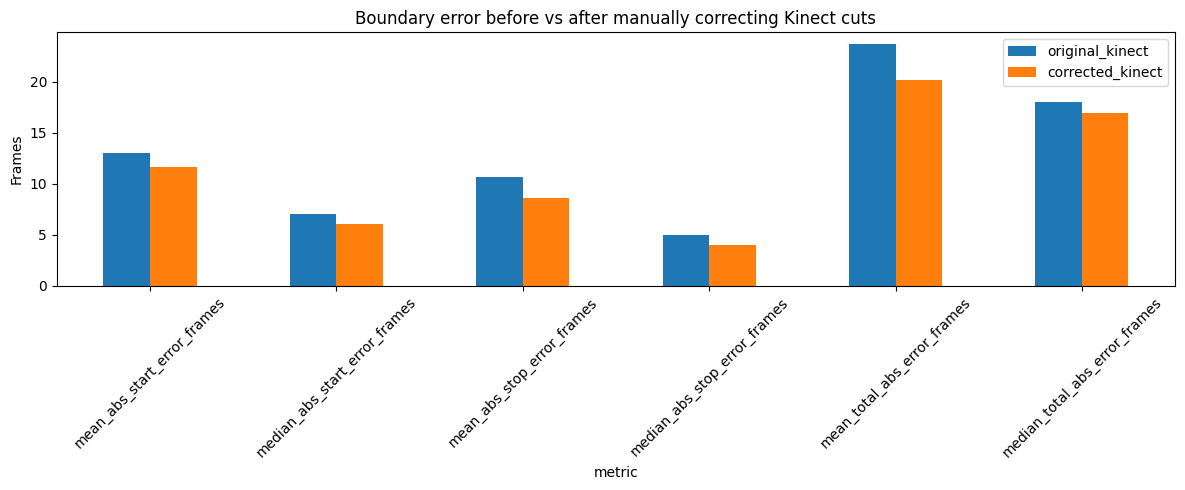

Saved corrected Kinect boundary comparison outputs.


In [85]:
# Compare boundary evaluation using original Kinect cuts vs manually corrected Kinect cuts.
# The model is NOT retrained here.
# Only the reference labels / true_start / true_stop are rebuilt from kinect_good_preprocessed_new.

KINECT_CUT_NEW_DIR = Path("../../../data/raw/kinect_good_preprocessed_new")

# 1. Build corrected dataset using the manually corrected cut files
new_triples_df = build_file_triples(
    MOVENET_DIR,
    KINECT_CUT_NEW_DIR,
    KINECT_UNCUT_DIR,
)

new_all_df = load_all_labeled_sequences(new_triples_df)

new_all_feat_df = new_all_df.copy()
new_all_feat_df = add_normalized_coordinates(new_all_feat_df)
new_all_feat_df = add_selected_distances(new_all_feat_df)
new_all_feat_df = add_selected_angles(new_all_feat_df)
new_all_feat_df = add_simple_velocity_features(new_all_feat_df)

print("Original matched sequences:", all_feat_df["sequence_id"].nunique())
print("Corrected matched sequences:", new_all_feat_df["sequence_id"].nunique())

# 2. Predict all original-label and corrected-label sequences with the already trained final champion
old_pred_df = predict_all_with_labels(
    source_feat_df=all_feat_df,
    model_to_use=final_champion_model,
    scaler_to_use=final_scaler,
)

new_pred_df = predict_all_with_labels(
    source_feat_df=new_all_feat_df,
    model_to_use=final_champion_model,
    scaler_to_use=final_scaler,
)

# 3. Build boundary tables
old_boundary_table = build_boundary_table(old_pred_df)
new_boundary_table = build_boundary_table(new_pred_df)

old_boundary_summary = summarize_boundary_table(
    old_boundary_table,
    value_column_name="original_kinect",
)

new_boundary_summary = summarize_boundary_table(
    new_boundary_table,
    value_column_name="corrected_kinect",
)

comparison_summary = old_boundary_summary.merge(
    new_boundary_summary,
    on="metric",
)

comparison_summary["difference_corrected_minus_original"] = (
    comparison_summary["corrected_kinect"]
    - comparison_summary["original_kinect"]
)

print("Boundary evaluation: original labels vs corrected labels")
display(comparison_summary)

# 4. Compare per-sequence boundary changes
old_compare = old_boundary_table[
    [
        "sequence_id",
        "true_start",
        "true_stop",
        "pred_start",
        "pred_stop",
        "abs_start_error_frames",
        "abs_stop_error_frames",
        "total_abs_error",
    ]
].copy()

old_compare = old_compare.rename(columns={
    "true_start": "old_true_start",
    "true_stop": "old_true_stop",
    "abs_start_error_frames": "old_abs_start_error",
    "abs_stop_error_frames": "old_abs_stop_error",
    "total_abs_error": "old_total_abs_error",
})

new_compare = new_boundary_table[
    [
        "sequence_id",
        "true_start",
        "true_stop",
        "pred_start",
        "pred_stop",
        "abs_start_error_frames",
        "abs_stop_error_frames",
        "total_abs_error",
    ]
].copy()

new_compare = new_compare.rename(columns={
    "true_start": "new_true_start",
    "true_stop": "new_true_stop",
    "abs_start_error_frames": "new_abs_start_error",
    "abs_stop_error_frames": "new_abs_stop_error",
    "total_abs_error": "new_total_abs_error",
})

per_sequence_comparison = old_compare.merge(
    new_compare,
    on=["sequence_id", "pred_start", "pred_stop"],
    how="inner",
)

per_sequence_comparison["total_error_improvement"] = (
    per_sequence_comparison["old_total_abs_error"]
    - per_sequence_comparison["new_total_abs_error"]
)

per_sequence_comparison = per_sequence_comparison.sort_values(
    "total_error_improvement",
    ascending=False,
).reset_index(drop=True)

print("Sequences with largest improvement after correcting Kinect cuts:")
display(per_sequence_comparison.head(20))

print("Sequences where corrected Kinect cuts made the error worse:")
display(per_sequence_comparison.tail(20))

# 5. Plot comparison
plot_metrics = [
    "mean_abs_start_error_frames",
    "median_abs_start_error_frames",
    "mean_abs_stop_error_frames",
    "median_abs_stop_error_frames",
    "mean_total_abs_error_frames",
    "median_total_abs_error_frames",
]

plot_df = comparison_summary[
    comparison_summary["metric"].isin(plot_metrics)
].set_index("metric")[["original_kinect", "corrected_kinect"]]

plot_df.plot(kind="bar", figsize=(12, 5))

plt.title("Boundary error before vs after manually correcting Kinect cuts")
plt.ylabel("Frames")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Save outputs
old_boundary_table.to_csv(
    output_dir / "a11_boundary_table_original_kinect_no_retrain.csv",
    index=False,
)

new_boundary_table.to_csv(
    output_dir / "a11_boundary_table_corrected_kinect_no_retrain.csv",
    index=False,
)

comparison_summary.to_csv(
    output_dir / "a11_original_vs_corrected_kinect_boundary_summary_no_retrain.csv",
    index=False,
)

per_sequence_comparison.to_csv(
    output_dir / "a11_original_vs_corrected_kinect_per_sequence_no_retrain.csv",
    index=False,
)

print("Saved corrected Kinect boundary comparison outputs.")

### Frame-level comparison using `kinect_good_preprocessed_new`

Frame-level metric comparison without retraining:


,metric,original_kinect_labels,corrected_kinect_labels,difference_corrected_minus_original
0,precision,0.953941,0.915152,-0.038789
1,recall,0.904540,0.919063,0.014524
2,f1_binary,0.928584,0.917104,-0.011480
3,f1_macro,0.902524,0.892198,-0.010326
4,f1_weighted,0.910369,0.897887,-0.012482
5,accuracy,0.909491,0.897952,-0.011539


Original labels confusion matrix:
[[11742  1039]
 [ 2271 21519]]

Corrected labels confusion matrix:
[[12195  1914]
 [ 1818 20644]]


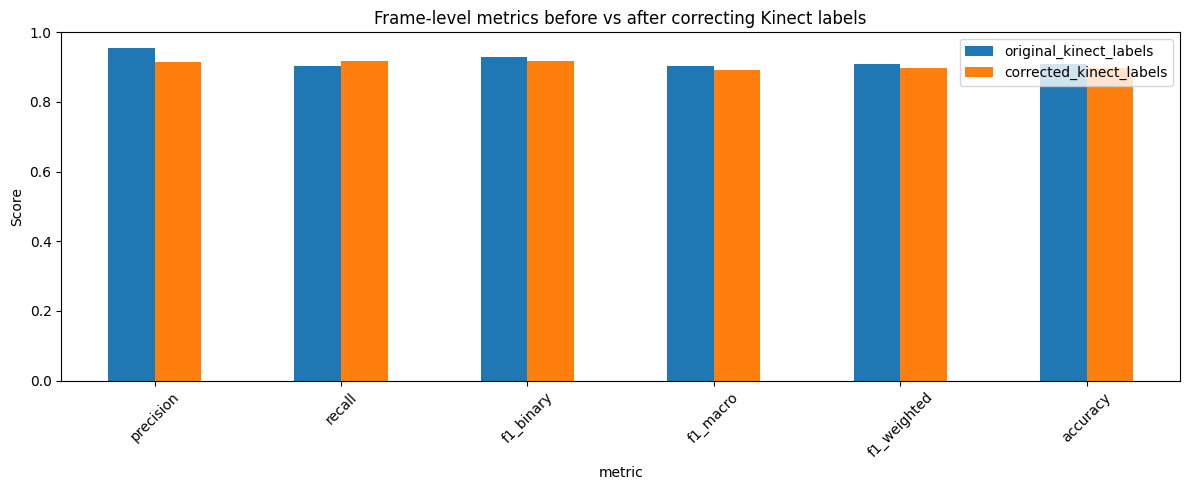

Saved corrected Kinect frame-level metric comparison.


In [86]:
# Frame-level metric comparison: original labels vs manually corrected labels
# No retraining. Same model predictions, but labels are rebuilt from each Kinect cut folder.

old_frame_metrics = calculate_frame_metrics(old_pred_df)
new_frame_metrics = calculate_frame_metrics(new_pred_df)

frame_metric_comparison = pd.DataFrame({
    "metric": list(old_frame_metrics.keys()),
    "original_kinect_labels": list(old_frame_metrics.values()),
    "corrected_kinect_labels": [new_frame_metrics[k] for k in old_frame_metrics.keys()],
})

frame_metric_comparison["difference_corrected_minus_original"] = (
    frame_metric_comparison["corrected_kinect_labels"]
    - frame_metric_comparison["original_kinect_labels"]
)

print("Frame-level metric comparison without retraining:")
display(frame_metric_comparison)

print("Original labels confusion matrix:")
print(confusion_matrix(old_pred_df["label"], old_pred_df["pred"]))

print("\nCorrected labels confusion matrix:")
print(confusion_matrix(new_pred_df["label"], new_pred_df["pred"]))

frame_metric_comparison.set_index("metric")[
    ["original_kinect_labels", "corrected_kinect_labels"]
].plot(kind="bar", figsize=(12, 5))

plt.title("Frame-level metrics before vs after correcting Kinect labels")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

frame_metric_comparison.to_csv(
    output_dir / "a11_original_vs_corrected_kinect_frame_metrics_no_retrain.csv",
    index=False,
)

print("Saved corrected Kinect frame-level metric comparison.")

### Does the corrected data give better results?

In [87]:
# Automatic interpretation helper
# Lower boundary error is better. Higher frame metrics are better.
# This cell does not decide whether the MODEL is better, because the model was not retrained.

boundary_metrics_where_lower_is_better = [
    "mean_abs_start_error_frames",
    "median_abs_start_error_frames",
    "mean_abs_stop_error_frames",
    "median_abs_stop_error_frames",
    "mean_total_abs_error_frames",
    "median_total_abs_error_frames",
]

boundary_check = comparison_summary[
    comparison_summary["metric"].isin(boundary_metrics_where_lower_is_better)
].copy()

n_boundary_metrics_improved = int(
    (boundary_check["difference_corrected_minus_original"] < 0).sum()
)

n_boundary_metrics_worse = int(
    (boundary_check["difference_corrected_minus_original"] > 0).sum()
)

frame_check = frame_metric_comparison.copy()

n_frame_metrics_improved = int(
    (frame_check["difference_corrected_minus_original"] > 0).sum()
)

n_frame_metrics_worse = int(
    (frame_check["difference_corrected_minus_original"] < 0).sum()
)

print("Interpretation:")
print(f"- Boundary metrics improved in {n_boundary_metrics_improved}/{len(boundary_check)} error metrics.")
print(f"- Boundary metrics became worse in {n_boundary_metrics_worse}/{len(boundary_check)} error metrics.")
print(f"- Frame-level metrics improved in {n_frame_metrics_improved}/{len(frame_check)} score metrics.")
print(f"- Frame-level metrics became worse in {n_frame_metrics_worse}/{len(frame_check)} score metrics.")

if n_boundary_metrics_improved > n_boundary_metrics_worse and n_frame_metrics_improved >= n_frame_metrics_worse:
    print("\nThe corrected Kinect labels make the existing model look better against the corrected ground truth.")
elif n_boundary_metrics_improved < n_boundary_metrics_worse and n_frame_metrics_improved < n_frame_metrics_worse:
    print("\nThe corrected Kinect labels do not improve the measured results for the existing model.")
else:
    print("\nThe result is mixed. Inspect the metric tables before claiming an improvement.")

print("\nImportant: this is not a better trained model yet. It is the same trained model evaluated with corrected labels.")
print("To claim a better model, rerun the notebook with KINECT_CUT_DIR pointing to kinect_good_preprocessed_new and compare the final independent test metrics.")

Interpretation:
- Boundary metrics improved in 6/6 error metrics.
- Boundary metrics became worse in 0/6 error metrics.
- Frame-level metrics improved in 1/6 score metrics.
- Frame-level metrics became worse in 5/6 score metrics.

The result is mixed. Inspect the metric tables before claiming an improvement.

Important: this is not a better trained model yet. It is the same trained model evaluated with corrected labels.
To claim a better model, rerun the notebook with KINECT_CUT_DIR pointing to kinect_good_preprocessed_new and compare the final independent test metrics.


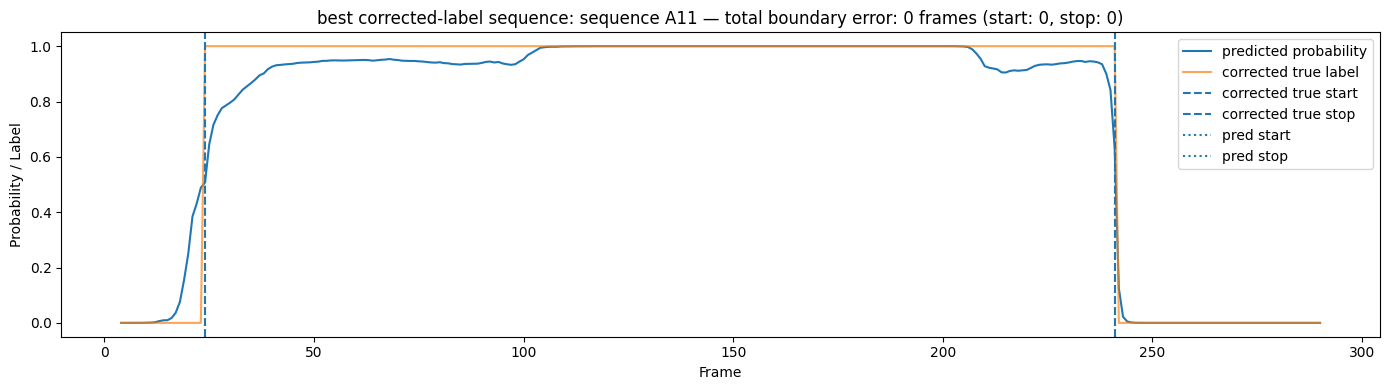

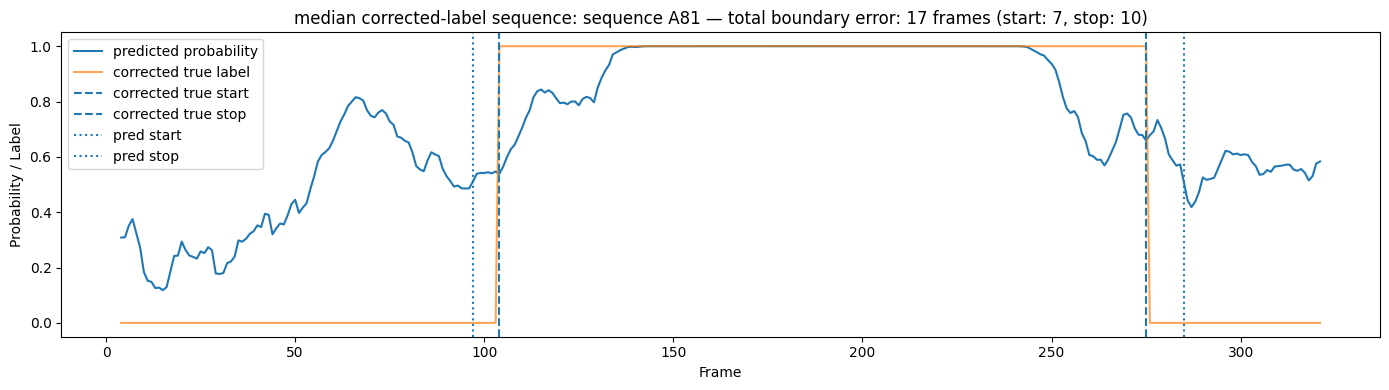

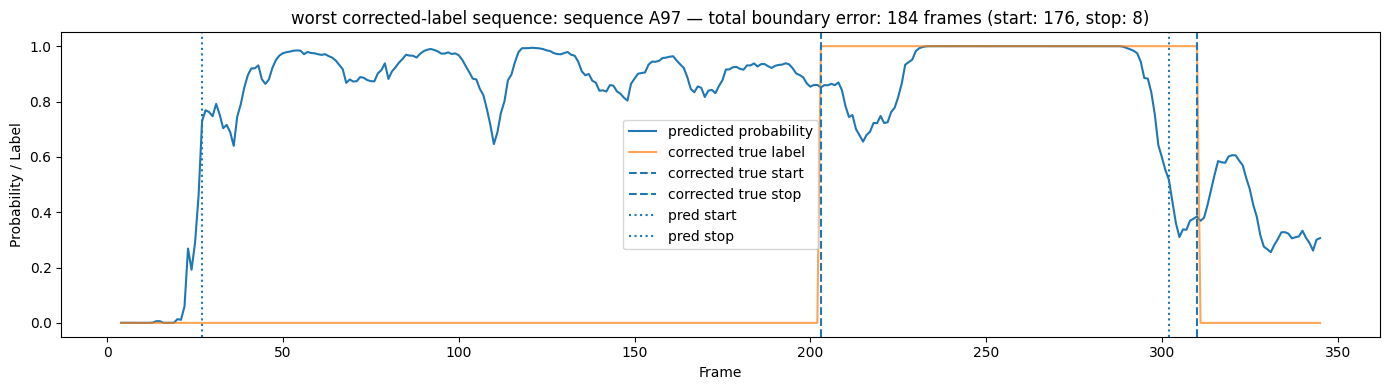

In [88]:
# Plot best, median, and worst corrected-Kinect sequences
# Same plot style as the final test plots, but using new_pred_df and new_boundary_table.
# These are evaluated against kinect_good_preprocessed_new labels.

corrected_ranked_sequences = new_boundary_table.copy()

corrected_ranked_sequences = corrected_ranked_sequences[
    corrected_ranked_sequences["detected_segment"] == 1
].copy()

if corrected_ranked_sequences.empty:
    print("No detected segments found, so no corrected-Kinect plots can be shown.")
else:
    corrected_ranked_sequences["total_abs_error"] = (
        corrected_ranked_sequences["abs_start_error_frames"]
        + corrected_ranked_sequences["abs_stop_error_frames"]
    )

    corrected_ranked_sequences = corrected_ranked_sequences.sort_values(
        "total_abs_error"
    ).reset_index(drop=True)

    corrected_best_seq = corrected_ranked_sequences.iloc[0]["sequence_id"]
    corrected_median_seq = corrected_ranked_sequences.iloc[
        len(corrected_ranked_sequences) // 2
    ]["sequence_id"]
    corrected_worst_seq = corrected_ranked_sequences.sort_values(
        "total_abs_error",
        ascending=False,
    ).iloc[0]["sequence_id"]

    corrected_sequences_to_plot = [
        ("best corrected-label sequence", corrected_best_seq),
        ("median corrected-label sequence", corrected_median_seq),
        ("worst corrected-label sequence", corrected_worst_seq),
    ]

    for plot_name, sequence_id in corrected_sequences_to_plot:
        plot_seq_df = new_pred_df[
            new_pred_df["sequence_id"] == sequence_id
        ].copy()

        plot_seq_df = plot_seq_df.sort_values("frame_ref")

        true_start = int(plot_seq_df["start_frame"].iloc[0])
        true_stop = int(plot_seq_df["stop_frame"].iloc[0])

        pred_start, pred_stop = longest_positive_run(
            plot_seq_df,
            pred_col="pred",
        )

        total_error = corrected_ranked_sequences.loc[
            corrected_ranked_sequences["sequence_id"] == sequence_id,
            "total_abs_error",
        ].iloc[0]

        start_error = corrected_ranked_sequences.loc[
            corrected_ranked_sequences["sequence_id"] == sequence_id,
            "abs_start_error_frames",
        ].iloc[0]

        stop_error = corrected_ranked_sequences.loc[
            corrected_ranked_sequences["sequence_id"] == sequence_id,
            "abs_stop_error_frames",
        ].iloc[0]

        plt.figure(figsize=(14, 4))

        plt.plot(
            plot_seq_df["frame_ref"],
            plot_seq_df["prob"],
            label="predicted probability",
        )

        plt.plot(
            plot_seq_df["frame_ref"],
            plot_seq_df["label"],
            label="corrected true label",
            alpha=0.7,
        )

        plt.axvline(
            true_start,
            linestyle="--",
            label="corrected true start",
        )

        plt.axvline(
            true_stop,
            linestyle="--",
            label="corrected true stop",
        )

        if pred_start is not None:
            plt.axvline(
                pred_start,
                linestyle=":",
                label="pred start",
            )

        if pred_stop is not None:
            plt.axvline(
                pred_stop,
                linestyle=":",
                label="pred stop",
            )

        plt.title(
            f"{plot_name}: sequence {sequence_id} — "
            f"total boundary error: {total_error:.0f} frames "
            f"(start: {start_error:.0f}, stop: {stop_error:.0f})"
        )

        plt.xlabel("Frame")
        plt.ylabel("Probability / Label")
        plt.legend()
        plt.tight_layout()
        plt.show()